# Quantitative Research -- Part 4: Regression

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ChrisW09/Quantitative-Research-Methods/blob/main/Part_4_Regression/Part_4_Regression.ipynb)

This notebook is the companion of the slide deck *Part 4: Regression*. Its sections follow
the slides with the same numbering, and the code cells use the same Python commands as the
slides (the "Try it yourself" links on the slides point to these sections). Run the cells
from top to bottom. For every exercise, try it yourself first in the *Your turn* cell, then
look at the solution cell.

## Contents

1. Relationship Between Two Metric Variables -- 1.1 Example and scatter plot, 1.2 Covariance and correlation
2. Simple Linear Regression -- 2.1 The best line, 2.2 Least squares, 2.3 Interpretation, 2.4 Exercises
3. Goodness of Fit: the Coefficient of Determination -- 3.1 Variance decomposition, 3.2 Coefficient of determination, 3.3 Useful transformations, 3.4 Exercises
4. Inference in Simple Regression -- 4.1 The regression model, 4.2 Sampling variability, 4.3 $t$-test for a coefficient, 4.4 Confidence intervals, 4.5 $p$-values and Python output, 4.6 Prediction, 4.7 Exercises
5. Multiple Linear Regression -- 5.1 From one to many explanatory variables, 5.2 Interpreting the coefficients, 5.3 Inference for single coefficients, 5.4 $F$-test, 5.5 Goodness of fit and model choice, 5.6 Qualitative explanatory variables, 5.7 Exercise: reading a full output
6. Summary

Appendix: Optional and Advanced Material -- A.1 Derivation of the OLS estimators, A.2 Minimum property of OLS, A.3 Residual analysis, A.4 Outliers and leverage, A.5 QQ-plot, A.6 Interactions, A.7 Diagnostics in multiple regression

Key Python commands (last cell)

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.width", 120)
pd.set_option("display.precision", 4)    # tables with 4 decimals, as on the slides
# numbers in cell outputs with 4 decimals
%precision 4
# summary() runs normality tests that warn for small n -- silence them (as in the script)
warnings.filterwarnings("ignore", category=UserWarning)

DATA_URL = "https://raw.githubusercontent.com/ChrisW09/Quantitative-Research-Methods/main/data/"
def load_data(name, **kwargs):
    """Local copy if the notebook runs inside the repo, otherwise download from GitHub."""
    local = Path("..") / "data" / name
    return pd.read_csv(local if local.exists() else DATA_URL + name, **kwargs)

## 1 Relationship Between Two Metric Variables

### 1.1 Example and scatter plot

Slides: *Relationship between two metric variables*, *Regression -- an example*, *Regression -- a warning*

A new lamp is sold in nine stores at different prices. The price is the **exogenous**
(explanatory) variable $X$, the sales quantity the **endogenous** variable $Y$.
Each pair $(x_i, y_i)$ comes from the same store.

**In words:** never sort $x$ and $y$ separately -- the pairs belong together.

In [2]:
# Lamp example: price (EUR) and sales quantity in nine stores -- used throughout the part
df = pd.DataFrame({"price":    [80, 85, 90, 95, 100, 105, 110, 115, 120],
                   "quantity": [20, 17, 15,  9,  11,   8,   4,   4,   2]})
df.T

,0,1,2,3,4,5,6,7,8
price,80,85,90,95,100,105,110,115,120
quantity,20,17,15,9,11,8,4,4,2


Slide: *Scatter plot*

Each observation $(x_i, y_i)$ is one point: the exogenous value on the $x$-axis, the
endogenous value on the $y$-axis.

**In words:** the cloud shows direction, strength and form of the relationship -- here
falling, strong and roughly linear.

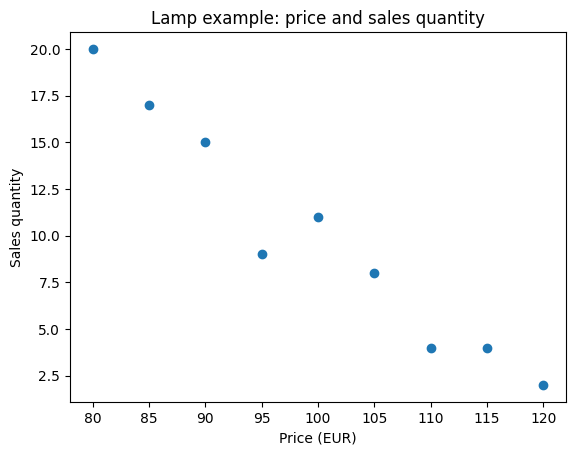

In [3]:
plt.scatter(df["price"], df["quantity"])
plt.xlabel("Price (EUR)"); plt.ylabel("Sales quantity"); plt.title("Lamp example: price and sales quantity")
plt.show()

### 1.2 Covariance and correlation

Slides: *Covariance: how do we measure the direction of a relationship?*, *Covariance*, *Covariance -- interpretation*, *Covariance -- lamp example*

$$s_{xy} = \frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar x)(y_i-\bar y) = \frac{S_{xy}}{n-1},
\qquad S_{xx} = \sum_{i=1}^{n}(x_i-\bar x)^2 \;\Rightarrow\; s_x^2 = \frac{S_{xx}}{n-1}$$

**In words:** most products $(x_i-\bar x)(y_i-\bar y)$ of the lamp data are negative, so the
covariance is negative: price and quantity move in opposite directions.

In [4]:
# Working table of the slide "Covariance -- lamp example"
x, y = df["price"], df["quantity"]
work = pd.DataFrame({"x - xbar": x - x.mean(), "y - ybar": y - y.mean(),
                     "(x - xbar)(y - ybar)": (x - x.mean()) * (y - y.mean()),
                     "(x - xbar)^2": (x - x.mean())**2, "(y - ybar)^2": (y - y.mean())**2})
print(work.T)
print("column sums:", work.sum().tolist())             # 0, 0, S_xy = -670, S_xx = 1500, S_yy = 316
print("s_xy = S_xy/(n-1) =", work["(x - xbar)(y - ybar)"].sum() / (len(x) - 1))   # -83.75
print("s_x^2 =", x.var(), "  s_y^2 =", y.var())        # 187.5, 39.5

                          0      1      2     3    4     5      6      7      8
x - xbar              -20.0  -15.0  -10.0  -5.0  0.0   5.0   10.0   15.0   20.0
y - ybar               10.0    7.0    5.0  -1.0  1.0  -2.0   -6.0   -6.0   -8.0
(x - xbar)(y - ybar) -200.0 -105.0  -50.0   5.0  0.0 -10.0  -60.0  -90.0 -160.0
(x - xbar)^2          400.0  225.0  100.0  25.0  0.0  25.0  100.0  225.0  400.0
(y - ybar)^2          100.0   49.0   25.0   1.0  1.0   4.0   36.0   36.0   64.0
column sums: [0.0, 0.0, -670.0, 1500.0, 316.0]
s_xy = S_xy/(n-1) = -83.75
s_x^2 = 187.5   s_y^2 = 39.5


**Data of the running exercise "online shop".** Advertising $x$ and revenue $y$ of an
online shop in five months (both in 1000 EUR). The data frame `shop` is entered once here
and reused in all online-shop exercises (1)--(10) and (A)--(C).

In [5]:
shop = pd.DataFrame({"adv": [1, 2, 3, 4, 5], "revenue": [21, 26, 24, 30, 29]})
shop.T

,0,1,2,3,4
adv,1,2,3,4,5
revenue,21,26,24,30,29


#### Exercise -- online shop (1): scatter plot and covariance

| Month $i$ | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| Advertising $x_i$ | 1 | 2 | 3 | 4 | 5 |
| Revenue $y_i$ | 21 | 26 | 24 | 30 | 29 |

1. Draw the scatter plot; describe the relationship.
2. Compute the means $\bar x$ and $\bar y$.
3. Compute $s_{xy}$ with a working table.

In [6]:
x, y = shop["adv"], shop["revenue"]      # data already entered above
# Your turn: scatter plot, means, working table and covariance s_xy

**Solution**

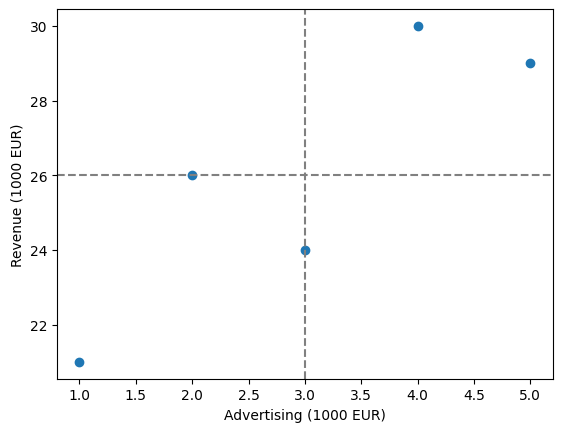

means: 3.0 26.0
           0  1  2  3  4
x - xbar  -2 -1  0  1  2
y - ybar  -5  0 -2  4  3
product   10  0  0  4  6
S_xy = 20.0   s_xy = 5.0


In [7]:
x, y = shop["adv"], shop["revenue"]
plt.scatter(x, y)                                        # (1) positive, roughly linear
plt.axvline(x.mean(), ls="--", c="grey"); plt.axhline(y.mean(), ls="--", c="grey")
plt.xlabel("Advertising (1000 EUR)"); plt.ylabel("Revenue (1000 EUR)"); plt.show()
print("means:", x.mean(), y.mean())                      # (2) 3.0, 26.0
products = (x - x.mean()) * (y - y.mean())
print(pd.DataFrame({"x - xbar": x - x.mean(), "y - ybar": y - y.mean(), "product": products}).astype(int).T)
print("S_xy =", products.sum(), "  s_xy =", x.cov(y))     # (3) 20.0, 5.0

Slides: *Correlation coefficient*, *Correlation coefficient -- strength of the relationship*

$$r_{xy} = \frac{s_{xy}}{s_x\,s_y}, \qquad -1 \le r_{xy} \le 1$$

Rule of thumb: $|r_{xy}| > 0.8$ strong, $0.5$ to $0.8$ moderate, $< 0.5$ weak.

**In words:** the correlation is a covariance without units -- the covariance of the
$z$-standardised variables.

In [8]:
x, y = df["price"], df["quantity"]
print("s_x =", round(x.std(), 4), "  s_y =", round(y.std(), 4))     # 13.6931, 6.2849
print("r_xy =", round(x.cov(y) / (x.std() * y.std()), 4))          # -0.9732: strongly negative

s_x = 13.6931   s_y = 6.2849
r_xy = -0.9732


#### Exercise -- online shop (2): correlation coefficient

Known from exercise (1): $n = 5$, $\bar x = 3$, $\bar y = 26$, $s_{xy} = 5$, $S_{xy} = 20$;
deviations $x_i - \bar x$: $-2, -1, 0, 1, 2$ and $y_i - \bar y$: $-5, 0, -2, 4, 3$.

1. Compute $S_{xx}$ and $S_{yy}$ from the deviations.
2. Compute $s_x$, $s_y$ and $r_{xy}$; check the result with $S_{xy}/\sqrt{S_{xx}S_{yy}}$.
3. Assess the strength and direction of the relationship.

In [9]:
x, y = shop["adv"], shop["revenue"]
# Your turn: S_xx, S_yy, s_x, s_y and r_xy

**Solution**

In [10]:
x, y = shop["adv"], shop["revenue"]
Sxx = ((x - x.mean())**2).sum(); Syy = ((y - y.mean())**2).sum()
print("S_xx =", Sxx, "  S_yy =", Syy)                                  # (1) 10, 54
print("s_x =", round(x.std(), 4), "  s_y =", round(y.std(), 4))        # (2) 1.5811, 3.6742
print("r_xy =", round(x.corr(y), 4), "  check:", round(20 / np.sqrt(Sxx * Syy), 4))   # 0.8607
# (3) |r| = 0.86 > 0.8: a strong positive linear relationship (not a causal statement)

S_xx = 10.0   S_yy = 54.0
s_x = 1.5811   s_y = 3.6742
r_xy = 0.8607   check: 0.8607


Slide: *Correlation coefficient -- limitations*

Correlation is symmetric ($r_{xy} = r_{yx}$), says nothing about causality and only measures
**linear** relationships.

**In words:** a perfect U-shape can have $r_{xy} = 0$ -- always look at the scatter plot first.

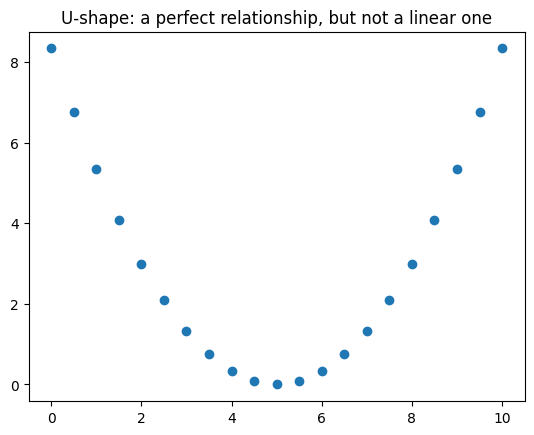

r = 0.0


In [11]:
u = pd.Series(np.arange(0, 10.5, 0.5)); v = (u - 5)**2 / 3     # an exact U-shape, symmetric about 5
plt.scatter(u, v); plt.title("U-shape: a perfect relationship, but not a linear one"); plt.show()
print("r =", round(abs(u.corr(v)), 4))                          # 0.0

Slide: *Covariance and correlation with Python* (the data frame `df` and the imports are
already defined above)

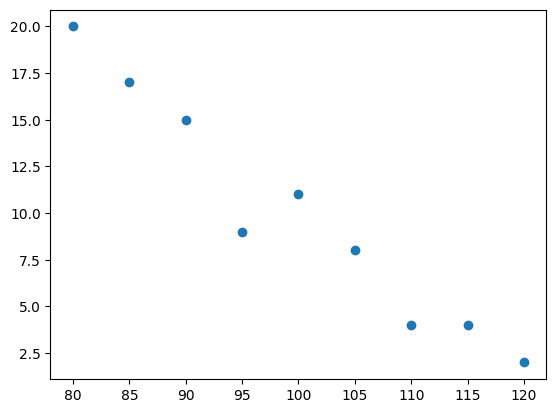

-83.75
-0.9732


In [12]:
plt.scatter(df["price"], df["quantity"])     # scatter plot
plt.show()
print(df["price"].cov(df["quantity"]))                 # -83.75  (divides by n-1)
print(round(df["price"].corr(df["quantity"]), 4))      # -0.9732 (Pearson is the default)

## 2 Simple Linear Regression

### 2.1 The best line

Slides: *From correlation to regression*, *Starting question: how is advertising related to revenue?*

Twelve stores: advertising budget $x$ and revenue $y$ of the last quarter (both in 1000 EUR).
Regression asks: how does $y$ change with $x$, and which $y$ do we expect?

**In words:** how much more revenue goes along with 1000 EUR more advertising, and which
revenue do we expect at 7000 EUR?

In [13]:
# Twelve stores (both in 1000 EUR) -- used in Sections 2 and 3
stores = pd.DataFrame({"adv":     [1, 3, 4, 5, 6, 8, 8, 9, 10, 11, 12, 13],
                       "revenue": [33, 30, 37, 33, 38, 41, 39, 43, 45, 40, 42, 47]})
x, y = stores["adv"], stores["revenue"]
print("r_xy =", round(x.corr(y), 4))                                     # 0.8803
print("xbar =", x.mean(), "  ybar =", y.mean())                          # 7.5, 39.0
print("S_xy =", ((x - x.mean()) * (y - y.mean())).sum(), "  S_xx =", ((x - x.mean())**2).sum(),
      "  S_yy =", ((y - y.mean())**2).sum())                              # 186, 155, 288

r_xy = 0.8803
xbar = 7.5   ybar = 39.0
S_xy = 186.0   S_xx = 155.0   S_yy = 288.0


Slides: *Which line describes the data best?*, *How do we describe a straight line mathematically?*, *Observed value, fitted value and residual*

Line $y = \beta_0 + \beta_1 x$; fitted value $\hat y_i = \hat\beta_0 + \hat\beta_1 x_i$;
residual $\hat u_i = y_i - \hat y_i$.

**In words:** the residual is the vertical distance between a point and the line --
positive above the line, negative below.

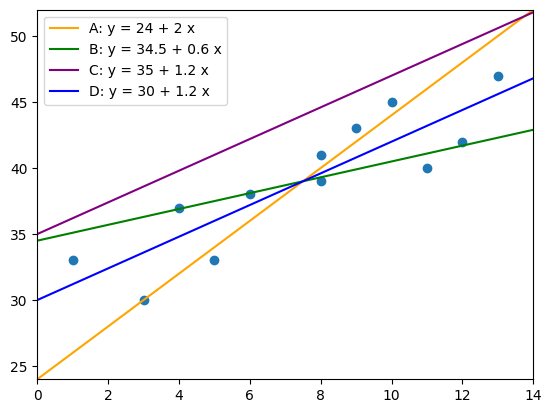

fitted: 42.0   residual: 3.0


In [14]:
lines = {"A": (24, 2), "B": (34.5, 0.6), "C": (35, 1.2), "D": (30, 1.2)}   # (intercept, slope)
x, y = stores["adv"], stores["revenue"]
plt.scatter(x, y)
for (name, (b0, b1)), col in zip(lines.items(), ["orange", "green", "purple", "blue"]):
    plt.axline((0, b0), slope=b1, color=col, label=f"{name}: y = {b0} + {b1} x")
plt.xlim(0, 14); plt.ylim(24, 52); plt.legend(); plt.show()
yhat9 = 30 + 1.2 * 10                          # store 9 (x = 10, y = 45), line D
print("fitted:", yhat9, "  residual:", 45 - yhat9)     # 42.0, 3.0

#### Exercise -- online shop (3): residuals of two lines

Two employees propose a line for the online shop: **line 1** $\hat y = 23 + x$ and
**line 2** $\hat y = 20 + 2x$.

1. Compute $\hat y_i$ and $\hat u_i$ for both lines.
2. Add up the residuals of each line.
3. Which line fits better by eye? Does the sum of the residuals show it?

In [15]:
x, y = shop["adv"], shop["revenue"]
# Your turn: fitted values, residuals and their sums for line 1 (23 + x) and line 2 (20 + 2x)

**Solution**

In [16]:
x, y = shop["adv"], shop["revenue"]
for name, (b0, b1) in {"line 1": (23, 1), "line 2": (20, 2)}.items():
    yhat = b0 + b1 * x
    u = y - yhat
    print(f"{name}: fitted {yhat.tolist()}, residuals {u.tolist()}, sum {u.sum()}")
# (3) line 2 fits visibly better -- yet both sums are 0: the sum cannot tell them apart

line 1: fitted [24, 25, 26, 27, 28], residuals [-3, 1, -2, 3, 1], sum 0
line 2: fitted [22, 24, 26, 28, 30], residuals [-1, 2, -2, 2, -1], sum 0


### 2.2 Least squares

Slides: *Why not simply add up the residuals?*, *The sum of residuals cannot tell good from bad lines*

**In words:** positive and negative residuals cancel out -- lines A, B and D all have the
residual sum 0, and the higher a line lies, the more negative the sum.

In [17]:
x, y = stores["adv"], stores["revenue"]
for name, (b0, b1) in lines.items():
    u = y - (b0 + b1 * x)
    print(f"line {name}: sum of residuals = {np.round(u.sum(), 6) + 0:6.1f}")      # 0, 0, -60, 0

line A: sum of residuals =    0.0
line B: sum of residuals =    0.0
line C: sum of residuals =  -60.0
line D: sum of residuals =    0.0


#### Exercise -- online shop (4): squaring the residuals

Residuals from exercise (3): line 1: $-3, 1, -2, 3, 1$; line 2: $-1, 2, -2, 2, -1$.

1. Square the residuals: $\hat u_i^{\,2}$.
2. Add up per line: $S = \sum \hat u_i^{\,2}$.
3. Which line has the smaller sum? Does this agree with your judgement by eye?

In [18]:
x, y = shop["adv"], shop["revenue"]
# Your turn: squared residuals and their sum S for both lines

**Solution**

In [19]:
x, y = shop["adv"], shop["revenue"]
for name, (b0, b1) in {"line 1": (23, 1), "line 2": (20, 2)}.items():
    u = y - (b0 + b1 * x)
    print(f"{name}: squares {(u**2).tolist()}, S = {(u**2).sum()}")   # S = 24 and 14
# (3) line 2 has the smaller sum of squares (14 < 24) -- as judged by eye

line 1: squares [9, 1, 4, 9, 1], S = 24
line 2: squares [1, 4, 4, 4, 1], S = 14


Slides: *Gauss: the method of least squares*, *Squaring the residuals of the twelve stores*, *Squared residuals as areas*, *Comparison: a poorly fitting line and the best line*

$$S = \sum_{i=1}^{n} \hat u_i^{\,2} = \sum_{i=1}^{n} (y_i - \hat y_i)^2$$

**In words:** square the residuals so that nothing cancels out, add them up and choose the
line with the smallest sum.

In [20]:
x, y = stores["adv"], stores["revenue"]
for name, (b0, b1) in lines.items():
    u = y - (b0 + b1 * x)
    print(f"line {name}: sum of squares S = {(u**2).sum():.1f}")   # 164.0, 120.6, 364.8, 64.8
print("squared residuals of D:", ((y - (30 + 1.2 * x))**2).round(2).tolist())

line A: sum of squares S = 164.0
line B: sum of squares S = 120.6
line C: sum of squares S = 364.8
line D: sum of squares S = 64.8
squared residuals of D: [3.24, 12.96, 4.84, 9.0, 0.64, 1.96, 0.36, 4.84, 9.0, 10.24, 5.76, 1.96]


Slides: *The minimisation problem: the objective function*, *From the minimisation problem to the OLS estimator in four steps*

$$S(\beta_0,\beta_1) = \sum_{i=1}^{n}(y_i - \beta_0 - \beta_1 x_i)^2, \qquad
(\hat\beta_0,\hat\beta_1) = \underset{\beta_0,\beta_1}{\arg\min}\; S(\beta_0,\beta_1)$$

**In words:** we look for the coefficient values with the smallest sum of squared residuals.
A coarse grid search over many candidate lines already finds line D.

In [21]:
def S(b0, b1, x=stores["adv"], y=stores["revenue"]):
    """Objective function of least squares: sum of squared residuals of the line b0 + b1 x."""
    return ((y - b0 - b1 * x)**2).sum()

print(round(S(24, 2), 1), round(S(30, 1.2), 1))           # 164.0 (line A), 64.8 (line D)
grid = [(b0, b1) for b0 in np.arange(25, 35.01, 0.5) for b1 in np.arange(0.5, 2.01, 0.05)]
best = min(grid, key=lambda c: S(*c))
print("grid minimum at b0 = %.1f, b1 = %.2f" % best)       # 30.0, 1.20

164 64.8
grid minimum at b0 = 30.0, b1 = 1.20


Slides: *The OLS estimator of the slope*, *The link to covariance and variance*, *Slope $=$ covariance over variance*

$$\hat\beta_1 = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2} = \frac{S_{xy}}{S_{xx}} = \frac{s_{xy}}{s_x^2}$$

**In words:** the slope is the covariance of $x$ and $y$ divided by the variance of $x$; the
factor $1/(n-1)$ cancels.

In [22]:
x, y = stores["adv"], stores["revenue"]
Sxy = ((x - x.mean()) * (y - y.mean())).sum(); Sxx = ((x - x.mean())**2).sum()
print("beta1 = S_xy/S_xx =", Sxy, "/", Sxx, "=", round(Sxy / Sxx, 4))         # 186/155 = 1.2
print("s_xy =", round(x.cov(y), 2), "  s_x^2 =", round(x.var(), 2),
      "  beta1 = s_xy/s_x^2 =", round(x.cov(y) / x.var(), 4))                 # 16.91, 14.09, 1.2

beta1 = S_xy/S_xx = 186.0 / 155.0 = 1.2
s_xy = 16.91   s_x^2 = 14.09   beta1 = s_xy/s_x^2 = 1.2


#### Exercise -- online shop (5): the OLS line of the online shop

Known from exercises (1) and (2): $\bar x = 3$, $\bar y = 26$, $s_{xy} = 5$, $s_x^2 = 2.5$
($S_{xy} = 20$, $S_{xx} = 10$).

1. Compute the slope $\hat\beta_1 = s_{xy}/s_x^2$ and check it with $S_{xy}/S_{xx}$.
2. Compute the intercept $\hat\beta_0 = \bar y - \hat\beta_1\bar x$ and write down the OLS line.
3. Which of the two lines of exercise (3) is the OLS line? What does this mean for its sum of squared residuals 14?
4. Interpret the slope in words.

In [23]:
x, y = shop["adv"], shop["revenue"]
# Your turn: slope, intercept, OLS line; compare the sums of squares of the two lines

**Solution**

In [24]:
x, y = shop["adv"], shop["revenue"]    # on the slide: x = pd.Series([1, 2, 3, 4, 5]); y = pd.Series([21, ...])
b1 = x.cov(y) / x.var(); b0 = y.mean() - b1 * x.mean()
print("beta1 =", b1, "  beta0 =", b0)                      # (1), (2) 2.0, 20.0 -> yhat = 20 + 2x
print(((y - (20 + 2 * x))**2).sum(), ((y - (23 + x))**2).sum())   # (3) 14 (OLS line = line 2), 24 (line 1)
print("centroid check:", b0 + b1 * x.mean())              # 26.0 = ybar
# (4) 1000 EUR more advertising goes along with 2000 EUR more revenue on average

beta1 = 2.0   beta0 = 20.0
14 24
centroid check: 26.0


Slides: *Intercept, OLS line and the answer*, *Both estimators at a glance*, *Step by step to the regression line*

$$\hat\beta_0 = \bar y - \hat\beta_1\bar x, \qquad \hat y = \hat\beta_0 + \hat\beta_1 x$$

**In words:** the OLS line passes through the centroid $(\bar x, \bar y)$; its residuals
satisfy $\sum \hat u_i = 0$ and $\sum x_i\hat u_i = 0$ (first-order conditions).

In [25]:
x, y = stores["adv"], stores["revenue"]
Sxy = ((x - x.mean()) * (y - y.mean())).sum(); Sxx = ((x - x.mean())**2).sum()
b1 = Sxy / Sxx; b0 = y.mean() - b1 * x.mean()
print("beta1 =", round(b1, 4), "  beta0 =", round(b0, 4))      # 1.2, 30.0: line D is the OLS line
print("yhat(7) =", round(b0 + b1 * 7, 4))                      # 38.4: answer to the starting question
u = y - (b0 + b1 * x)
print("first-order conditions hold:", np.isclose(u.sum(), 0), np.isclose((x * u).sum(), 0))

beta1 = 1.2   beta0 = 30.0
yhat(7) = 38.4
first-order conditions hold: True True


#### Exercise -- online shop (6): the OLS line for a second shop

The retailer opens a second online shop (five months, both variables in 1000 EUR):

| Month $i$ | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| Advertising $x_i$ | 2 | 4 | 5 | 6 | 8 |
| Revenue $y_i$ | 12 | 20 | 19 | 23 | 31 |

1. Compute $\bar x$, $\bar y$, $S_{xy}$ and $S_{xx}$ with a working table.
2. Determine $\hat\beta_1 = S_{xy}/S_{xx}$ and $\hat\beta_0 = \bar y - \hat\beta_1\bar x$; write down the regression line.
3. Interpret the slope in words.
4. Compute $\hat y_i$ and $\hat u_i$; check $\sum \hat u_i = 0$.
5. Draw the line into the scatter plot.

In [26]:
shopB = pd.DataFrame({"adv": [2, 4, 5, 6, 8], "revenue": [12, 20, 19, 23, 31]})
# Your turn: working table, OLS estimates, fitted values, residuals and the plot

**Solution**

               0  1  2  3   4
x - xbar      -3 -1  0  1   3
y - ybar      -9 -1 -2  2  10
product       27  1  0  2  30
(x - xbar)^2   9  1  0  1   9
xbar = 5.0  ybar = 21.0  S_xy = 60.0  S_xx = 20.0
beta1 = 3.0   beta0 = 6.0
fitted: [12.0, 18.0, 21.0, 24.0, 30.0]  residuals: [0.0, 2.0, -2.0, -1.0, 1.0]  sum: 0.0


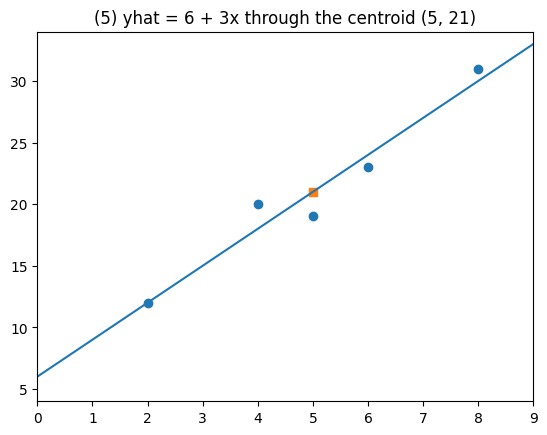

In [27]:
xB, yB = shopB["adv"], shopB["revenue"]
work = pd.DataFrame({"x - xbar": xB - xB.mean(), "y - ybar": yB - yB.mean(),
                     "product": (xB - xB.mean()) * (yB - yB.mean()), "(x - xbar)^2": (xB - xB.mean())**2})
print(work.astype(int).T)
print("xbar =", xB.mean(), " ybar =", yB.mean(), " S_xy =", work["product"].sum(),
      " S_xx =", work["(x - xbar)^2"].sum())                     # (1) 5, 21, 60, 20
b1 = work["product"].sum() / work["(x - xbar)^2"].sum(); b0 = yB.mean() - b1 * xB.mean()
print("beta1 =", b1, "  beta0 =", b0)        # (2) 3.0, 6.0 -> yhat = 6 + 3x; (3) +1000 EUR adv: +3000 EUR revenue
yhat = b0 + b1 * xB
print("fitted:", yhat.tolist(), " residuals:", (yB - yhat).tolist(), " sum:", (yB - yhat).sum())   # (4)
plt.scatter(xB, yB); plt.axline((0, b0), slope=b1); plt.scatter([xB.mean()], [yB.mean()], marker="s")
plt.xlim(0, 9); plt.ylim(4, 34); plt.title("(5) yhat = 6 + 3x through the centroid (5, 21)"); plt.show()

### 2.3 Interpretation

Slides: *How do we interpret the slope?*, *How do we interpret the intercept?*, *Interpretation at a glance -- and predictions*

$$\Delta\hat y = \hat\beta_1\cdot\Delta x, \qquad \hat\beta_0 = \hat y\,\big|_{x=0}$$

**In words:** each additional 1000 EUR of advertising goes along with 1200 EUR more revenue
on average; predictions inside the observed range (1 to 13) are interpolations, outside
they are extrapolations.

In [28]:
b0, b1 = 30, 1.2                                          # twelve stores
print(b0 + b1 * 5, b0 + b1 * 10)                          # 36.0, 42.0: +5 in x gives +6 in yhat
print(round(b0 + b1 * 9.5, 4), round(b0 + b1 * 25, 4))    # 41.4 (interpolation), 60.0 (extrapolation!)

36.0 42.0
41.4 60.0


Slides: *Second example: the lamp -- calculation*, *The lamp: interpreting the coefficients*

$\hat\beta_1 = -83.75/187.5 = -0.4467$, $\hat\beta_0 = 10 - (-0.4467)\cdot 100 = 54.67$.

**In words:** if the price rises by 1 euro, the sales quantity falls on average by 0.4467
units; the intercept (sales at a price of 0 euros) has no substantive meaning.

In [29]:
x, y = df["price"], df["quantity"]
print("s_xy =", x.cov(y), "  s_x^2 =", x.var())                 # -83.75, 187.5
b1 = x.cov(y) / x.var(); b0 = y.mean() - b1 * x.mean()
print("beta1 =", round(b1, 4), "  beta0 =", round(b0, 2))       # -0.4467, 54.67

s_xy = -83.75   s_x^2 = 187.5
beta1 = -0.4467   beta0 = 54.67


Slide: *Linear regression with Python*

**In words:** `smf.ols()` solves the minimisation problem of this section; `"y ~ x"` reads
"$y$ explained by $x$".

In [30]:
beta1 = df["price"].cov(df["quantity"]) / df["price"].var()   # -0.4467
beta0 = df["quantity"].mean() - beta1 * df["price"].mean()   # 54.6667
print(round(beta1, 4), round(beta0, 4))

-0.4467 54.6667


Intercept    54.6667
price        -0.4467
dtype: float64
3.552713678800501e-14


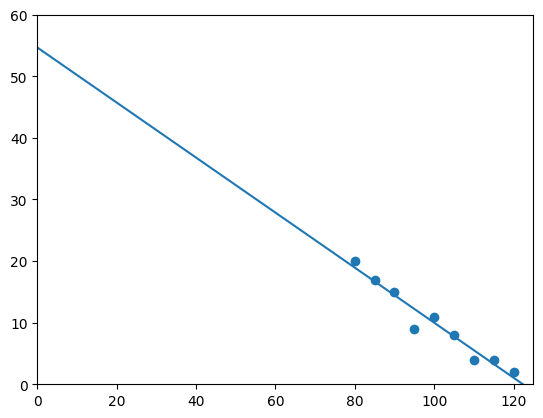

In [31]:
import statsmodels.formula.api as smf
reg = smf.ols("quantity ~ price", data=df).fit()  # quantity explained by price
print(reg.params)                 # Intercept 54.6667, price -0.4467
print(reg.resid.sum())            # 0 (up to rounding): first-order condition
plt.scatter(df["price"], df["quantity"]); plt.xlim(0, 125); plt.ylim(0, 60)
plt.axline((0, reg.params["Intercept"]), slope=reg.params["price"])
plt.show()

### 2.4 Exercises

#### Exercise -- interpreting coefficients and making predictions

Furniture store, six weeks (both in 1000 EUR); Python gives the OLS line $\hat y = 40 + 2.5x$.

| Advertising $x_i$ | 2 | 4 | 6 | 8 | 10 | 12 |
|---|---|---|---|---|---|---|
| Weekly revenue $y_i$ | 44 | 49 | 58 | 62 | 61 | 71 |

1. Interpret $\hat\beta_0 = 40$ and $\hat\beta_1 = 2.5$ in context (with units). Is $\hat\beta_0$ meaningful?
2. What weekly revenue is expected for advertising of 5 and of 30 thousand euros? How reliable are the two predictions?
3. By how much does the expected revenue change with 2000 euros more advertising -- from 4 to 6 and from 10 to 12?
4. Advertising is now measured in euros instead of thousands of euros: what are $\hat\beta_0$ and $\hat\beta_1$? And if revenue is also measured in euros?

In [32]:
fs = pd.DataFrame({"adv": [2, 4, 6, 8, 10, 12], "revenue": [44, 49, 58, 62, 61, 71]})
# Your turn: fit the line, predict at 5 and 30, compare 4 -> 6 and 10 -> 12, change the units

**Solution**

In [33]:
reg = smf.ols("revenue ~ adv", data=fs).fit()
print(reg.params)                                        # (1) 40.0  2.5
print(reg.predict(pd.DataFrame({"adv": [5, 30]})))       # (2) 52.5 (interpolation), 115.0 (extrapolation!)
print(reg.predict(pd.DataFrame({"adv": [4, 6, 10, 12]})).round(4).tolist())   # (3) 50 -> 55 and 65 -> 70: +5 both times
print("largest |residual|:", round(reg.resid.abs().max(), 4))      # 4.0
print(smf.ols("revenue ~ I(1000 * adv)", data=fs).fit().params)      # (4) 40.0  0.0025
fs_eur = 1000 * fs                                       # both variables in euros
print(smf.ols("revenue ~ adv", data=fs_eur).fit().params)            # 40000.0  2.5

Intercept    40.0
adv           2.5
dtype: float64
0     52.5
1    115.0
dtype: float64
[50.0, 55.0, 65.0, 70.0]
largest |residual|: 4.0
Intercept        40.0000
I(1000 * adv)     0.0025
dtype: float64
Intercept    40000.0
adv              2.5
dtype: float64


#### Exercise -- a falling price--demand line

Weekly demand $y$ (units sold) and price $x$ (EUR) in five weeks; given
$\bar x = 14$, $\bar y = 48$, $S_{xx} = 40$, $S_{xy} = -120$.

| Price $x_i$ (EUR) | 10 | 12 | 14 | 16 | 18 |
|---|---|---|---|---|---|
| Units sold $y_i$ | 64 | 50 | 46 | 42 | 38 |

1. Compute $\hat\beta_1$ and $\hat\beta_0$ and write down the fitted line.
2. Interpret $\hat\beta_1$ in one sentence. Is its sign plausible?
3. Predict the demand at 15 euros and at 42 euros; judge both.
4. Compute the residual of week 1, $(x_1, y_1) = (10, 64)$. Above or below the line?
5. Which Python command predicts the demand at $x = 15$ from the fitted model `reg = smf.ols("units ~ price", data=dem).fit()`?

In [34]:
dem = pd.DataFrame({"price": [10, 12, 14, 16, 18], "units": [64, 50, 46, 42, 38]})
# Your turn

**Solution**

In [35]:
b1 = -120 / 40; b0 = 48 - b1 * 14
print("beta1 =", b1, "  beta0 =", b0)            # (1) -3.0, 90.0 -> yhat = 90 - 3x; (2) -3 units per euro
reg = smf.ols("units ~ price", data=dem).fit()
print(reg.params.round(4).tolist())              # the same line from smf.ols
print(reg.predict(pd.DataFrame({"price": [15]})))     # (5) 45.0 -- (3) inside [10, 18]: plausible
print(b0 + b1 * 42)                              # (3) -36.0: extrapolation, impossible
print("residual week 1:", 64 - (b0 + b1 * 10))   # (4) +4.0: above the line

beta1 = -3.0   beta0 = 90.0
[90.0, -3.0]
0    45.0
dtype: float64
-36.0
residual week 1: 4.0


## 3 Goodness of Fit: the Coefficient of Determination

### 3.1 Variance decomposition

Slides: *How much does the line explain?*, *Splitting one deviation into two parts*, *Sum-of-squares decomposition: square and add up*

$$y_i - \bar y = (\hat y_i - \bar y) + (y_i - \hat y_i), \qquad
\underbrace{\sum (y_i-\bar y)^2}_{\text{TSS}} = \underbrace{\sum (\hat y_i-\bar y)^2}_{\text{ESS}} + \underbrace{\sum \hat u_i^{\,2}}_{\text{RSS}}$$

**In words:** without $x$ we predict $\bar y$ (sum of squares 288); with the line the sum of
squares falls to 64.8 -- the decomposition holds for the sums, not for each store.

In [36]:
reg12 = smf.ols("revenue ~ adv", data=stores).fit()      # twelve stores: yhat = 30 + 1.2 x
y = stores["revenue"]
terms = pd.DataFrame({"(y - ybar)^2": (y - y.mean())**2,
                      "(yhat - ybar)^2": (reg12.fittedvalues - y.mean())**2,
                      "u^2": reg12.resid**2})
print(terms.round(2).T)
TSS12, ESS12, RSS12 = terms.sum()
print("TSS =", round(TSS12, 4), " ESS =", round(ESS12, 4), " RSS =", round(RSS12, 4))   # 288 = 223.2 + 64.8
print("store 12: total", 47 - 39, " explained", round(45.6 - 39, 1), " residual", round(47 - 45.6, 1))

                    0      1      2     3     4     5     6      7     8      9      10     11
(y - ybar)^2     36.00  81.00   4.00  36.0  1.00  4.00  0.00  16.00  36.0   1.00   9.00  64.00
(yhat - ybar)^2  60.84  29.16  17.64   9.0  3.24  0.36  0.36   3.24   9.0  17.64  29.16  43.56
u^2               3.24  12.96   4.84   9.0  0.64  1.96  0.36   4.84   9.0  10.24   5.76   1.96
TSS = 288.0  ESS = 223.2  RSS = 64.8
store 12: total 8  explained 6.6  residual 1.4


#### Exercise -- online shop (7): the sum-of-squares decomposition

Known: $\bar y = 26$, $y_i - \bar y$: $-5, 0, -2, 4, 3$; OLS line $\hat y = 20 + 2x$ with
$\hat y_i$: $22, 24, 26, 28, 30$ and $\hat u_i$: $-1, 2, -2, 2, -1$.

1. Compute TSS, ESS and RSS.
2. Check: does $\text{TSS} = \text{ESS} + \text{RSS}$ hold?
3. Does the decomposition also hold month by month?

In [37]:
x, y = shop["adv"], shop["revenue"]
# Your turn: TSS, ESS and RSS of the OLS line 20 + 2x

**Solution**

In [38]:
x, y = shop["adv"], shop["revenue"]
yhat = 20 + 2 * x
TSS = ((y - y.mean())**2).sum(); ESS = ((yhat - y.mean())**2).sum(); RSS = ((y - yhat)**2).sum()
print("TSS =", TSS, "  ESS =", ESS, "  RSS =", RSS)            # (1) 54, 40, 14
print("TSS == ESS + RSS:", TSS == ESS + RSS)                  # (2) True: 54 = 40 + 14
print("month 1:", (21 - 26)**2, "vs", (22 - 26)**2, "+", (21 - 22)**2)   # (3) 25 != 16 + 1

TSS = 54.0   ESS = 40.0   RSS = 14
TSS == ESS + RSS: True
month 1: 25 vs 16 + 1


Slide: *The decomposition and least squares*

The mixed term vanishes because of the first-order conditions, so the decomposition only
holds for the OLS line: ESS is maximal, RSS minimal.

**In words:** for line A it fails: $620 + 164 \ne 288$.

In [39]:
y = stores["revenue"]
ESS_A = ((24 + 2 * stores["adv"] - y.mean())**2).sum()
print("line A: ESS_A =", ESS_A, "  ESS_A + RSS_A =", ESS_A + 164, "!= 288")     # 620, 784

line A: ESS_A = 620.0   ESS_A + RSS_A = 784.0 != 288


### 3.2 Coefficient of determination

Slides: *The coefficient of determination $R^2$*, *The extreme cases: $R^2 = 1$ and $R^2 = 0$*

$$R^2 = \frac{\text{ESS}}{\text{TSS}} = 1 - \frac{\text{RSS}}{\text{TSS}}, \qquad 0 \le R^2 \le 1$$

**In words:** $R^2$ is the share of the variation of $y$ that the regression on $x$ explains --
here 77.5 %.

In [40]:
print(round(ESS12 / TSS12, 4), round(1 - RSS12 / TSS12, 4), round(reg12.rsquared, 4))   # 0.775 three times
xe = np.arange(1, 9)                                      # schematic data of the slide
print("R^2 = 1:", round(smf.ols("y ~ x", data=pd.DataFrame({"x": xe, "y": 2 + 1.5 * xe})).fit().rsquared, 4))
r0 = smf.ols("y ~ x", data=pd.DataFrame({"x": xe, "y": [5, 7, 4, 6, 6, 4, 7, 5]})).fit()
print("R^2 = 0: line", r0.params.round(4).tolist(), " R^2 =", round(r0.rsquared, 4))    # 5.5 + 0 x, 0.0

0.775 0.775 0.775
R^2 = 1: 1.0
R^2 = 0: line [5.5, 0.0]  R^2 = 0.0


Slide: *$R^2$ and the correlation coefficient*

$$\text{ESS} = \hat\beta_1^{\,2} S_{xx}, \qquad R^2 = \frac{S_{xy}^2}{S_{xx}S_{yy}} = r_{xy}^2$$

**In words:** in simple regression $R^2$ is the square of the correlation coefficient.

In [41]:
r = stores["adv"].corr(stores["revenue"])
print("r =", round(r, 4), "  r^2 =", round(r**2, 4), "  ESS = 1.2^2 * 155 =", round(1.2**2 * 155, 4))   # 0.8803, 0.775, 223.2

r = 0.8803   r^2 = 0.775   ESS = 1.2^2 * 155 = 223.2


Slides: *What $R^2$ does -- and does not -- tell you*, *Assessing $R^2$*

Rule of thumb: $R^2 < 0.6$ weak, $0.6 \le R^2 < 0.8$ moderate, $R^2 \ge 0.8$ good fit.

**In words:** a high $R^2$ does not prove that a line is the right model -- the ten regions
have $R^2 = 0.81$, yet the points clearly bend.

[28.6667, 2.3333]  R^2 = 0.81


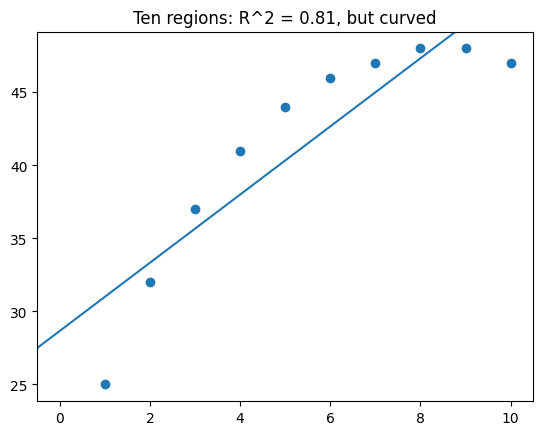

In [42]:
sat = pd.DataFrame({"adv": np.arange(1, 11), "revenue": [25, 32, 37, 41, 44, 46, 47, 48, 48, 47]})
reg_sat = smf.ols("revenue ~ adv", data=sat).fit()
print(reg_sat.params.round(4).tolist(), " R^2 =", round(reg_sat.rsquared, 4))   # 28.6667 + 2.3333 x, 0.81
plt.scatter(sat["adv"], sat["revenue"]); plt.axline((0, reg_sat.params["Intercept"]), slope=reg_sat.params["adv"])
plt.title("Ten regions: R^2 = 0.81, but curved"); plt.show()

#### Exercise -- online shop (8): computing and assessing $R^2$

Known: exercise (7): $\text{TSS} = 54$, $\text{ESS} = 40$, $\text{RSS} = 14$; exercise (2): $r_{xy} = 0.8607$.

1. Compute $R^2$ in two ways: via ESS and via RSS.
2. Check the result with $r_{xy}$ from exercise (2).
3. Interpret $R^2$ in words and assess the fit with the rule of thumb.
4. True or false? "$R^2 = 0.74$ means that 74 % of the months lie exactly on the line." Justify briefly.

In [43]:
TSS, ESS, RSS, r = 54, 40, 14, 0.8607
# Your turn

**Solution**

In [44]:
print(round(40 / 54, 4), round(1 - 14 / 54, 4), round(0.8607**2, 4))   # (1), (2) 0.7407 0.7407 0.7408
# (3) 74 % of the variation is explained: 0.6 <= 0.74 < 0.8, a moderate fit
reg = smf.ols("revenue ~ adv", data=shop).fit()
print(round(reg.ssr, 4), reg.centered_tss, round(reg.rsquared, 4))   # 14.0  54.0  0.7407 (RSS, TSS, R^2)
print("residuals:", reg.resid.round(4).tolist())           # (4) false: no month lies on the line

0.7407 0.7407 0.7408
14.0 54.0 0.7407
residuals: [-1.0, 2.0, -2.0, 2.0, -1.0]


Slide: *Coefficient of determination -- lamp example*

$\text{TSS} = 316$, $\text{ESS} = \hat\beta_1^{\,2} S_{xx} = 299.27$, $\text{RSS} = 16.73$,
$R^2 = 0.9470$.

**In words:** about 95 % of the variation of the sales quantity is explained (linearly) by
the price; the sign of the relationship is in $\hat\beta_1$, not in $R^2$.

In [45]:
x, y = df["price"], df["quantity"]
Sxx_l = ((x - x.mean())**2).sum(); Sxy_l = ((x - x.mean()) * (y - y.mean())).sum()
TSS_l = ((y - y.mean())**2).sum(); ESS_l = (Sxy_l / Sxx_l)**2 * Sxx_l
print("TSS =", TSS_l, "  ESS =", round(ESS_l, 2), "  RSS =", round(TSS_l - ESS_l, 2),
      "  R^2 =", round(ESS_l / TSS_l, 4))                       # 316, 299.27, 16.73, 0.947

TSS = 316.0   ESS = 299.27   RSS = 16.73   R^2 = 0.947


Slide: *Coefficient of determination in Python*

**In words:** `summary()` reports further quantities (standard errors, $t$-values,
$p$-values) -- they follow in Section 4.

In [46]:
reg = smf.ols("quantity ~ price", data=df).fit()     # the lamp model (re-fitted here)
print(reg.summary())           # full output, incl. "R-squared: 0.947"

                            OLS Regression Results                            
Dep. Variable:               quantity   R-squared:                       0.947
Model:                            OLS   Adj. R-squared:                  0.939
Method:                 Least Squares   F-statistic:                     125.2
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           1.02e-05
Time:                        15:30:35   Log-Likelihood:                -15.561
No. Observations:                   9   AIC:                             35.12
Df Residuals:                       7   BIC:                             35.52
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     54.6667      4.025     13.581      0.0

In [47]:
print(round(reg.rsquared, 4))                              # 0.9470
RSS = (reg.resid**2).sum()                                 # 16.7333
TSS = ((df["quantity"] - df["quantity"].mean())**2).sum()  # 316
print(round(RSS, 4), TSS, round(1 - RSS / TSS, 4))         # three ways to the same value:
print(round(df["price"].corr(df["quantity"])**2, 4))       # simple regression only

0.947
16.7333 316.0 0.947
0.947


#### Exercise -- from sums of squares to the correlation coefficient

Heating costs of a shop in five weeks; from Python: OLS line $\hat y = 78 - 3x$,
$\text{TSS} = 1000$, $\text{RSS} = 190$.

| Week $i$ | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| Mean outside temperature $x_i$ (°C) | 0 | 3 | 6 | 9 | 12 |
| Heating costs $y_i$ (EUR per day) | 82 | 65 | 63 | 41 | 49 |

1. Compute ESS and $R^2$; interpret $R^2$.
2. Determine $r_{xy}$ from $R^2$ -- justify the sign.
3. Assess the fit with the rule of thumb.
4. Check: recompute ESS via $\hat\beta_1^{\,2} S_{xx}$.

In [48]:
hc = pd.DataFrame({"temp": [0, 3, 6, 9, 12], "cost": [82, 65, 63, 41, 49]})
# Your turn

**Solution**

In [49]:
print("ESS =", 1000 - 190, "  R^2 =", (1000 - 190) / 1000)     # (1) 810, 0.81; (3) >= 0.8: good fit
print("r =", -np.sqrt(0.81))                                     # (2) -0.9: sign of beta1 = -3
Sxx_hc = ((hc["temp"] - hc["temp"].mean())**2).sum()
print("S_xx =", Sxx_hc, "  ESS = (-3)^2 * S_xx =", 9 * Sxx_hc)   # (4) 90, 810
reg = smf.ols("cost ~ temp", data=hc).fit()
print(round(reg.rsquared, 4))                  # 0.81
print(round(hc["temp"].corr(hc["cost"]), 4))   # -0.9
print(round(reg.ssr, 4), round(reg.ess, 4))    # 190.0  810.0  (careful: ssr = RSS, ess = ESS)

ESS = 810   R^2 = 0.81
r = -0.9
S_xx = 90.0   ESS = (-3)^2 * S_xx = 810.0
0.81
-0.9
190.0 810.0


### 3.3 Useful transformations

Slides: *Shortcut: three sums are enough*, *Why the factor $1/(n-1)$ cancels*, *All key figures from three sums*, *Example: the twelve stores from three sums*

$$\hat\beta_1 = \frac{S_{xy}}{S_{xx}}, \quad r_{xy} = \frac{S_{xy}}{\sqrt{S_{xx}S_{yy}}}, \quad
R^2 = \frac{S_{xy}^2}{S_{xx}S_{yy}}, \quad \text{ESS} = \hat\beta_1 S_{xy}, \quad \text{RSS} = S_{yy} - \hat\beta_1 S_{xy}$$

**In words:** all key figures of simple regression follow from $S_{xx}$, $S_{yy}$ and
$S_{xy}$ -- without $1/(n-1)$ factors and roots of rounded variances.

In [50]:
print("r =", round(186 / np.sqrt(155 * 288), 4), "  R^2 =", 186**2, "/", 155 * 288, "=", round(186**2 / (155 * 288), 4))
print("ESS =", round(1.2 * 186, 4), "  RSS =", round(288 - 1.2 * 186, 4))      # 223.2, 64.8

r = 0.8803   R^2 = 34596 / 44640 = 0.775
ESS = 223.2   RSS = 64.8


Slide: *Sums without a deviation table: the shift theorem*

$$S_{xy} = \sum x_i y_i - n\bar x\bar y, \qquad S_{xx} = \sum x_i^2 - n\bar x^2, \qquad S_{yy} = \sum y_i^2 - n\bar y^2$$

**In words:** add up the raw products and squares and subtract the mean part once.

In [51]:
x, y = shop["adv"], shop["revenue"]; n = len(x)
print((x * y).sum(), (x**2).sum(), (y**2).sum())                     # 410, 55, 3434
print((x * y).sum() - n * x.mean() * y.mean(), (x**2).sum() - n * x.mean()**2,
      (y**2).sum() - n * y.mean()**2)                                  # S_xy = 20, S_xx = 10, S_yy = 54

410 55 3434
20.0 10.0 54.0


Slide: *Correlation as a standardised slope*

$$r_{xy} = \hat\beta_1\cdot\frac{s_x}{s_y}$$

**In words:** measure $x$ and $y$ in standard deviations, and the slope becomes the
correlation coefficient.

In [52]:
print("stores: s_x/s_y =", round(np.sqrt(155 / 288), 4), "  r = 1.2 * s_x/s_y =", round(1.2 * np.sqrt(155 / 288), 4))
print("lamp: beta1 = r * s_y/s_x =",
      round(df["price"].corr(df["quantity"]) * df["quantity"].std() / df["price"].std(), 4))   # -0.4467

stores: s_x/s_y = 0.7336   r = 1.2 * s_x/s_y = 0.8803
lamp: beta1 = r * s_y/s_x = -0.4467


Slide: *Three sums with Python*

In [53]:
stores = pd.DataFrame({"adv":     [1, 3, 4, 5, 6, 8, 8, 9, 10, 11, 12, 13],
                       "revenue": [33, 30, 37, 33, 38, 41, 39, 43, 45, 40, 42, 47]})
x, y = stores["adv"], stores["revenue"]
Sxx = ((x - x.mean())**2).sum()                   # 155.0
Syy = ((y - y.mean())**2).sum()                   # 288.0 (= TSS)
Sxy = ((x - x.mean()) * (y - y.mean())).sum()     # 186.0
b1 = Sxy / Sxx; b0 = y.mean() - b1 * x.mean()     # 1.2  30.0
print(Sxx, Syy, Sxy, round(b1, 4), round(b0, 4))
print(round(Sxy / np.sqrt(Sxx * Syy), 4), round(b1 * Sxy, 4))   # r = 0.8803, ESS = 223.2
print((x * y).sum() - len(x) * x.mean() * y.mean())   # 186.0 = Sxy (shift theorem)
reg = smf.ols("revenue ~ adv", data=stores).fit() # TSS = ESS + RSS, R^2:
reg.centered_tss, reg.ess, reg.ssr, reg.rsquared  # 288.0 = 223.2 + 64.8; R^2 = 0.775

155.0 288.0 186.0 1.2 30.0
0.8803 223.2
186.0


(288.0000, 223.2000, 64.8000, 0.7750)

### 3.4 Exercises

#### Exercise -- reading a simple regression output in Python

For $n = 12$ students the study hours $x$ and the exam points $y$ (at most 100) were
recorded; the observed study hours range from 5 to 24. Excerpt of the output:

```
                 coef    std err          t      P>|t|      [0.025      0.975]
Intercept     28.0000      3.962      7.068      0.000      19.173      36.827
hours          2.5000      0.264      9.487      0.000       1.913       3.087
R-squared: 0.900
```
Also known: $\bar x = 14$, $S_{xx} = 360$, $\text{TSS} = 2500$. (The data in the cell
below are constructed to give exactly this output.)

1. Write down the fitted line and interpret $\hat\beta_1$ and $\hat\beta_0$ in context.
2. Predict the points for 16 and for 30 study hours; judge both predictions.
3. Determine the correlation coefficient $r_{xy}$ from the output.
4. Compute ESS and RSS and check the result via $\hat\beta_1^{\,2} S_{xx}$.
5. Name a third variable that could explain part of the association.

In [54]:
st = pd.DataFrame({"hours":  [5, 7, 8, 10, 12, 14, 16, 17, 17, 18, 20, 24],
                   "points": [36, 50, 47, 51, 63, 71, 62, 65, 75, 69, 76, 91]})
reg = smf.ols("points ~ hours", data=st).fit()
# Your turn

**Solution**

In [55]:
reg = smf.ols("points ~ hours", data=st).fit()
print(reg.summary().tables[1])                       # (1) yhat = 28 + 2.5 x
print("R^2 =", round(reg.rsquared, 4))               # 0.9
print(reg.predict(pd.DataFrame({"hours": [16, 30]})).round(4).tolist())   # (2) 68 (plausible), 103 (> 100: extrapolation)
print("r =", round(np.sqrt(reg.rsquared), 4), "=", round(st["hours"].corr(st["points"]), 4))   # (3) +0.9487
print("ESS =", round(reg.ess, 4), " RSS =", round(reg.ssr, 4), " beta1^2 S_xx =", 2.5**2 * 360)  # (4) 2250, 250, 2250
# (5) e.g. prior knowledge or motivation drives both study time and points

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     28.0000      3.962      7.068      0.000      19.173      36.827
hours          2.5000      0.264      9.487      0.000       1.913       3.087
R^2 = 0.9
[68.0, 103.0]
r = 0.9487 = 0.9487
ESS = 2250.0  RSS = 250.0  beta1^2 S_xx = 2250.0


#### Exercise -- body heights and shoe sizes (tasks 1--2)

Body heights $k_i$ (cm) and shoe sizes $s_i$ of $n = 15$ persons (body heights as in Part 2);
auxiliary sums $\sum k_i = 2553$, $\sum s_i = 602$, $\sum k_i s_i = 102\,932$,
$\sum k_i^2 = 436\,643$, $\sum s_i^2 = 24\,272$. Model: $s_i = \beta_0 + \beta_1 k_i + u_i$.

- **Task 1:** scatter plot; covariance and correlation coefficient.
- **Task 2:** regression line and interpretation, coefficient of determination $R^2$.

(Residual plot and QQ-plot of this regression: exercise in Appendix A.5; inference: Section 4.7.)

In [56]:
ks = pd.DataFrame({
    "k": [164, 162, 168, 198, 166, 166, 192, 160, 151, 175, 180, 160, 168, 175, 168],
    "s": [39, 38, 39, 46, 40, 39, 45, 37, 36, 42, 43, 38, 41, 40, 39]})
# Your turn

**Solution**

auxiliary sums: 2553 602 102932 436643 24272
S_ks = 471.6  S_kk = 2122.4  S_ss = 111.7333
cov = 33.6857  s_k = 12.3126  s_s = 2.8251  r = 0.9684


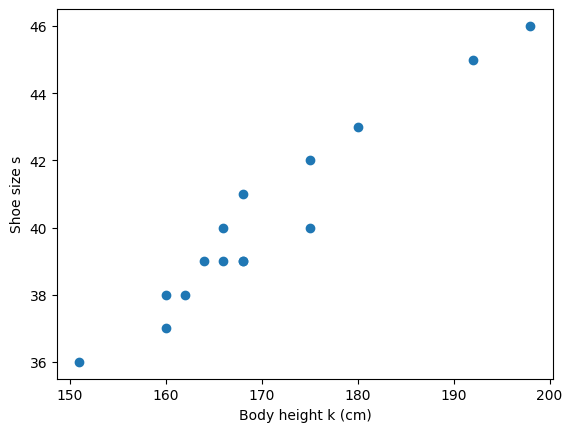

[2.3147, 0.2222]  R^2 = 0.9379
ESS = b1 * S_ks = 104.79  RSS = 6.94


In [57]:
k, s = ks["k"], ks["s"]; n = len(ks)
print("auxiliary sums:", k.sum(), s.sum(), (k * s).sum(), (k**2).sum(), (s**2).sum())
S_ks = (k * s).sum() - k.sum() * s.sum() / n             # shift theorem, no rounded means
S_kk = (k**2).sum() - k.sum()**2 / n
S_ss = (s**2).sum() - s.sum()**2 / n
print("S_ks =", round(S_ks, 4), " S_kk =", round(S_kk, 4), " S_ss =", round(S_ss, 4))   # 471.6, 2122.4, 111.7333
print("cov =", round(k.cov(s), 4), " s_k =", round(k.std(), 4), " s_s =", round(s.std(), 4),
      " r =", round(k.corr(s), 4))                       # Task 1: 33.6857, 12.3126, 2.8251, 0.9684
plt.scatter(k, s); plt.xlabel("Body height k (cm)"); plt.ylabel("Shoe size s"); plt.show()
reg_ks = smf.ols("s ~ k", data=ks).fit()
print(reg_ks.params.round(4).tolist(), " R^2 =", round(reg_ks.rsquared, 4))   # Task 2: 2.3147 + 0.2222 k, 0.9379
print("ESS = b1 * S_ks =", round(reg_ks.params["k"] * S_ks, 2),
      " RSS =", round(S_ss - reg_ks.params["k"] * S_ks, 2))                  # 104.79, 6.94

## 4 Inference in Simple Regression

### 4.1 The regression model

Slides: *From describing the data to the regression model*, *What do we assume about the error term?*

$$y_i = \beta_0 + \beta_1 x_i + u_i, \qquad E(u_i) = 0,\ \operatorname{Var}(u_i) = \sigma^2,\
\operatorname{Cov}(u_i, u_j) = 0,\ u_i \sim N(0, \sigma^2)$$

**In words:** the error term $u_i$ is not observable; the residuals $\hat u_i = y_i - \hat y_i$
are its estimates and are used to check the assumptions (Appendix A.3--A.5).

In [58]:
reg = smf.ols("quantity ~ price", data=df).fit()     # lamp model
reg.resid                                             # residuals: estimates of the error terms u_i

0    1.0667
1    0.3000
2    0.5333
3   -3.2333
4    1.0000
5    0.2333
6   -1.5333
7    0.7000
8    0.9333
dtype: float64

### 4.2 Sampling variability

Slides: *Why regression coefficients carry uncertainty*, *Population line vs. sample lines*, *Sampling distribution of the slope*

$$\hat\beta_1 \sim N\!\left(\beta_1, \frac{\sigma^2}{S_{xx}}\right), \qquad \operatorname{SE}(\hat\beta_1) = \frac{\sigma}{\sqrt{S_{xx}}}$$

**In words:** every sample gives its own line; the standard deviation of the simulated slopes
is the standard error. (Simulation with the lamp prices, as in the figure on the slide.)

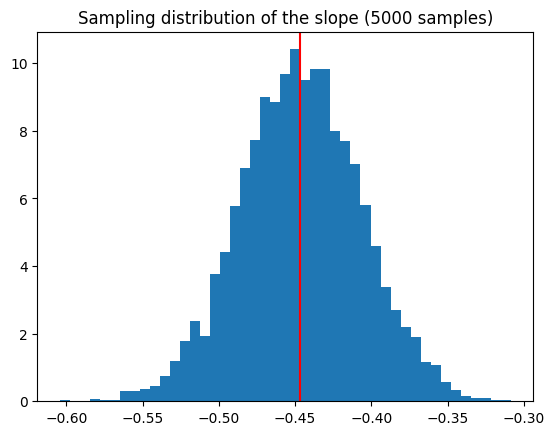

sd of the simulated slopes: 0.0394   sigma/sqrt(S_xx): 0.0399


In [59]:
rng = np.random.default_rng(2026)
x = df["price"].to_numpy(); n = len(x)
b0_true, b1_true = reg.params["Intercept"], reg.params["price"]   # population line of the simulation
sigma = np.sqrt(reg.scale); Sxx = ((x - x.mean())**2).sum()
slopes = []
for r in range(5000):
    y_sim = b0_true + b1_true * x + rng.normal(0, sigma, n)          # a new sample of nine stores
    slopes.append(((x - x.mean()) * (y_sim - y_sim.mean())).sum() / Sxx)
plt.hist(slopes, bins=45, density=True); plt.axvline(b1_true, color="red")
plt.title("Sampling distribution of the slope (5000 samples)"); plt.show()
print("sd of the simulated slopes:", round(np.std(slopes), 4), "  sigma/sqrt(S_xx):", round(sigma / np.sqrt(Sxx), 4))

Slides: *Estimating $\sigma$: the residual standard error*, *Standard errors -- lamp example*

$$\hat\sigma = \sqrt{\frac{\text{RSS}}{n-2}}, \qquad \operatorname{SE}(\hat\beta_1) = \frac{\hat\sigma}{\sqrt{S_{xx}}}, \qquad
\operatorname{SE}(\hat\beta_0) = \hat\sigma\sqrt{\frac1n + \frac{\bar x^2}{S_{xx}}}$$

**In words:** a typical store deviates by about 1.5 lamps from the line; the slope is
uncertain by about $\pm 0.04$.

In [60]:
x = df["price"]; n = len(df); Sxx = ((x - x.mean())**2).sum()
sigma_hat = np.sqrt((reg.resid**2).sum() / (n - 2))           # = np.sqrt(reg.scale)
se_b1 = sigma_hat / np.sqrt(Sxx)
se_b0 = sigma_hat * np.sqrt(1 / n + x.mean()**2 / Sxx)
print(round(sigma_hat, 4), round(se_b1, 5), round(se_b0, 4))   # 1.5461, 0.03992, 4.0252
print(reg.bse)                                                 # the same standard errors from statsmodels

1.5461 0.03992 4.0252
Intercept    4.0252
price        0.0399
dtype: float64


#### Exercise -- online shop (9): residual standard error and standard error

Back to the first five months: $\hat y = 20 + 2x$ with $n = 5$, $S_{xx} = 10$ and
$\text{RSS} = 14$ (exercises (2) and (7)).

1. Compute the residual standard error $\hat\sigma$.
2. Compute the standard error $\operatorname{SE}(\hat\beta_1)$.
3. Interpret both numbers in words.

In [61]:
n_shop, Sxx_shop, RSS_shop = 5, 10, 14
# Your turn

**Solution**

In [62]:
sigma_hat = np.sqrt(14 / (5 - 2)); se = sigma_hat / np.sqrt(10)
print(round(sigma_hat, 4), round(np.sqrt(10), 4), round(se, 4))    # (1), (2) 2.1602, 3.1623, 0.6831
reg_shop = smf.ols("revenue ~ adv", data=shop).fit()
print(round(np.sqrt(reg_shop.scale), 4), round(reg_shop.bse["adv"], 4))   # the same from statsmodels
# (3) a typical month deviates by about 2160 EUR from the line; the slope 2 is uncertain by about +-0.68

2.1602 3.1623 0.6831
2.1602 0.6831


### 4.3 $t$-test for a coefficient

Slides: *The first question: is there any relationship at all?*, *The $t$-statistic -- the same recipe as in Part 3*, *The test recipe for a regression coefficient*, *$t$-test -- lamp example*

$$H_0: \beta_1 = 0 \text{ vs. } H_1: \beta_1 \ne 0, \qquad T = \frac{\hat\beta_1 - \beta_{1,0}}{\operatorname{SE}(\hat\beta_1)} \sim t_{n-2},
\qquad \text{reject if } |T| > t_{1-\alpha/2,\,n-2}$$

**In words:** how many standard errors is the estimate away from the hypothesised value?
For the lamp: more than eleven.

In [63]:
n = len(df)
T = reg.params["price"] / reg.bse["price"]
print("T =", round(T, 2), "  t_0.975;7 =", round(stats.t.ppf(0.975, df=n - 2), 4),
      "  p =", f"{2 * stats.t.cdf(-abs(T), df=n - 2):.3g}")          # -11.19, 2.3646, 1.02e-05

T = -11.19   t_0.975;7 = 2.3646   p = 1.02e-05


#### Exercise -- online shop (10): is the slope significant?

From exercise (9): $\hat\beta_1 = 2$, $\operatorname{SE}(\hat\beta_1) = 0.6831$, $n = 5$. Hint: $t_{0.975;\,3} = 3.182$.

1. Test $H_0: \beta_1 = 0$ against $H_1: \beta_1 \ne 0$ at $\alpha = 0.05$.
2. $R^2 = 0.74$ looked quite good. Why is the test result nevertheless so weak?

In [64]:
beta1_shop, se_shop, n_shop = 2, 0.6831, 5
# Your turn

**Solution**

In [65]:
T_shop = 2 / 0.6831
print("T =", round(T_shop, 3), "  t_0.975;3 =", round(stats.t.ppf(0.975, 3), 3),
      "  p =", round(2 * stats.t.sf(abs(T_shop), 3), 3))   # (1) 2.928 < 3.182: keep H0 (p = 0.061)
print(reg_shop.tvalues.round(4).tolist(), reg_shop.pvalues.round(4).tolist())   # the same from statsmodels
# (2) only n - 2 = 3 degrees of freedom: large critical value and large standard error

T = 2.928   t_0.975;3 = 3.182   p = 0.061
[8.8273, 2.9277] [0.0031, 0.0611]


Slides: *Testing other hypothesised values*, *Two $t$-tests in one picture*

$H_0: \beta_1 = -0.5$: $T = (-0.4467 + 0.5)/0.03992 = 1.336$, $p = 0.223$.

**In words:** the claim "half a lamp per euro" is compatible with the data -- but not proven.

In [66]:
n = len(df)
T2 = (reg.params["price"] - (-0.5)) / reg.bse["price"]
print("T =", round(T2, 3), "  p =", round(2 * stats.t.sf(abs(T2), df=n - 2), 3))     # 1.336, 0.223

T = 1.336   p = 0.223


Slides: *One-sided test for the slope*, *Before you test -- the assumptions checklist*

$H_1: \beta_1 < 0$: reject if $T < -t_{1-\alpha,\,n-2} = -1.8946$; $p = F_{t,7}(T)$.

**In words:** fix the direction before looking at the data; statsmodels always reports the
two-sided $p$-value.

In [67]:
T = reg.params["price"] / reg.bse["price"]; n = len(df)
print("t_0.95;7 =", round(stats.t.ppf(0.95, df=n - 2), 4),
      "  left-sided p =", f"{stats.t.cdf(T, df=n - 2):.3g}")     # 1.8946, 5.08e-06 (about 0.000005)

t_0.95;7 = 1.8946   left-sided p = 5.08e-06


### 4.4 Confidence intervals

Slides: *Confidence interval for $\beta_1$*, *Confidence interval -- lamp example*, *Confidence intervals -- interpretation pitfalls*

$$\text{CI}_{1-\alpha}(\beta_1) = \Bigl[\hat\beta_1 \pm t_{1-\alpha/2,\,n-2}\cdot\operatorname{SE}(\hat\beta_1)\Bigr]$$

**In words:** the procedure covers the true slope in 95 % of all samples; values between
$-0.54$ and $-0.35$ lamps per euro are compatible with the data.

In [68]:
n = len(df); t_crit = stats.t.ppf(0.975, df=n - 2)
b1, se_b1 = reg.params["price"], reg.bse["price"]
print("margin =", round(t_crit * se_b1, 4), "  CI = [", round(b1 - t_crit * se_b1, 4), ";",
      round(b1 + t_crit * se_b1, 4), "]")                        # 0.0944, [-0.5411; -0.3523]
reg.conf_int(alpha=0.05)                                          # beta0: [45.15; 64.18]

margin = 0.0944   CI = [ -0.5411 ; -0.3523 ]


,0,1
Intercept,45.1486,64.1847
price,-0.5411,-0.3523


#### Exercise -- standard error, $t$ and confidence interval

A simple linear regression on $n = 10$ observations gives $\hat\beta_1 = 2.5$, residual
standard error $\hat\sigma = 4.0$ and $S_{xx} = 16$. Hint: $t_{0.975;\,8} = 2.306$.

1. Compute the standard error $\operatorname{SE}(\hat\beta_1)$.
2. Compute the $t$-statistic for $H_0: \beta_1 = 0$.
3. Compute the 95 % confidence interval for $\beta_1$.
4. Is the slope significant at the 5 % level? Justify in two ways.

In [69]:
b1_e, sigma_e, Sxx_e, n_e = 2.5, 4.0, 16, 10
# Your turn

**Solution**

In [70]:
b1_e, sigma_e, Sxx_e, n_e = 2.5, 4.0, 16, 10
se_e = sigma_e / np.sqrt(Sxx_e)                   # (1) 1.0 (divide by sqrt(S_xx), not by sqrt(n))
T_e = b1_e / se_e                                 # (2) 2.5
t_e = stats.t.ppf(0.975, df=n_e - 2)              # 2.306
print(se_e, T_e, round(t_e, 3), "  CI:", round(b1_e - t_e * se_e, 3), round(b1_e + t_e * se_e, 3))  # (3) [0.194; 4.806]
print("p =", round(2 * stats.t.sf(abs(T_e), df=n_e - 2), 3))   # (4) 0.037 < 0.05; also 0 lies outside the CI

1.0 2.5 2.306   CI: 0.194 4.806
p = 0.037


### 4.5 $p$-values and Python output

Slide: *The $p$-value of a coefficient*

$$p = P\bigl(|T| \ge |T_{\text{obs}}| \mid H_0\bigr) = 2\,F_{t,n-2}\bigl(-|T_{\text{obs}}|\bigr)$$

**In words:** $p < \alpha$ $\Leftrightarrow$ $|T| > t_{1-\alpha/2,\,n-2}$ $\Leftrightarrow$
hypothesised value outside the CI.

In [71]:
n = len(df)
for beta10 in (0, -0.5):
    Tb = (reg.params["price"] - beta10) / reg.bse["price"]
    print(f"H0: beta1 = {beta10}: T = {Tb:.2f}, p = {2 * stats.t.cdf(-abs(Tb), df=n - 2):.2g}")   # 1e-05, 0.22

H0: beta1 = 0: T = -11.19, p = 1e-05
H0: beta1 = -0.5: T = 1.34, p = 0.22


Slide: *Reading the regression output in Python*

`coef`, `std err`: $\hat\beta_j$, $\operatorname{SE}(\hat\beta_j)$; `t`, `P>|t|`: test of
$H_0: \beta_j = 0$; `[0.025 0.975]`: 95 % CI; `F-statistic` $= T^2$ in simple regression;
$\hat\sigma$ = `np.sqrt(reg.scale)` is not part of the summary.

In [72]:
print(reg.summary())
print(np.sqrt(reg.scale))           # sigma-hat: not part of the summary

                            OLS Regression Results                            
Dep. Variable:               quantity   R-squared:                       0.947
Model:                            OLS   Adj. R-squared:                  0.939
Method:                 Least Squares   F-statistic:                     125.2
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           1.02e-05
Time:                        15:30:35   Log-Likelihood:                -15.561
No. Observations:                   9   AIC:                             35.12
Df Residuals:                       7   BIC:                             35.52
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     54.6667      4.025     13.581      0.0

In [73]:
print(reg.bse.round(5).tolist(), [f"{pv:.3g}" for pv in reg.pvalues])   # exact standard errors and p-values
print("F = T^2:", round(reg.fvalue, 1), round(reg.tvalues["price"]**2, 1))   # 125.2

[4.02519, 0.03992] ['2.76e-06', '1.02e-05']
F = T^2: 125.2 125.2


Slide: *Significant $\neq$ important*

Advertising data ($n = 200$): sales on TV budget, $\hat\beta_1 = 0.0475$, $\text{CI}_{0.95} = [0.0422; 0.0528]$.

**In words:** the $p$-value measures evidence, not size -- report the estimate together with
its confidence interval.

In [74]:
ad = load_data("Advertising.csv", index_col=0)      # used again in Section 5
m_tv = smf.ols("sales ~ TV", data=ad).fit()
print(round(m_tv.params["TV"], 4), round(m_tv.bse["TV"], 4), round(m_tv.tvalues["TV"], 2))   # 0.0475, 0.0027, 17.67
m_tv.conf_int().loc["TV"]                                                                     # [0.0422; 0.0528]

0.0475 0.0027 17.67


0    0.0422
1    0.0528
Name: TV, dtype: float64

### 4.6 Prediction

Slides: *Two questions about a new $x_0$*, *Prediction -- lamp example*

$$\text{CI: } \hat y_0 \pm t_{1-\alpha/2,\,n-2}\,\hat\sigma\sqrt{\frac1n + \frac{(x_0-\bar x)^2}{S_{xx}}}, \qquad
\text{PI: } \hat y_0 \pm t_{1-\alpha/2,\,n-2}\,\hat\sigma\sqrt{1 + \frac1n + \frac{(x_0-\bar x)^2}{S_{xx}}}$$

**In words:** the confidence interval is for the mean sales of all stores with price $x_0$,
the prediction interval for one single store -- and always wider.

In [75]:
reg = smf.ols("quantity ~ price", data=df).fit()
n = len(df); x = df["price"]; Sxx = ((x - x.mean())**2).sum()           # 9, 1500
sigma_hat = np.sqrt(reg.scale); t_crit = stats.t.ppf(0.975, df=n - 2)   # 1.5461, 2.3646
x0 = 110
y0 = reg.params["Intercept"] + reg.params["price"] * x0                 # 5.53
half_ci = t_crit * sigma_hat * np.sqrt(1 / n + (x0 - 100)**2 / Sxx)     # 1.54
half_pi = t_crit * sigma_hat * np.sqrt(1 + 1 / n + (x0 - 100)**2 / Sxx) # 3.97
print(f"yhat0 = {y0:.2f}, CI [{y0 - half_ci:.2f}; {y0 + half_ci:.2f}], PI [{y0 - half_pi:.2f}; {y0 + half_pi:.2f}]")

yhat0 = 5.53, CI [3.99; 7.07], PI [1.57; 9.50]


Slide: *Confidence band vs. prediction band*

**In words:** both bands are narrowest at $\bar x = 100$; at $x_0 = 125$ the line predicts
$-1.17$ lamps -- impossible, an extrapolation.

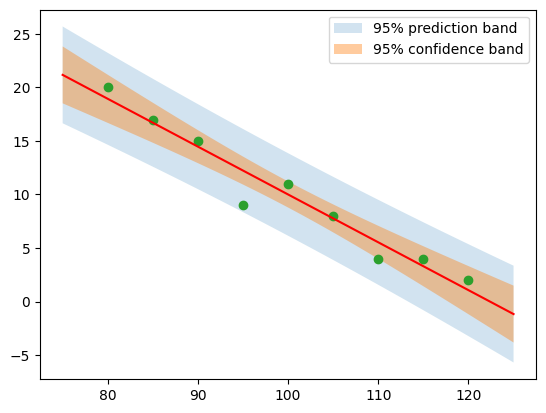

prediction at 125 EUR: -1.17


In [76]:
grid = pd.DataFrame({"price": np.linspace(75, 125, 200)})
band = reg.get_prediction(grid).summary_frame(alpha=0.05)
plt.fill_between(grid["price"], band["obs_ci_lower"], band["obs_ci_upper"], alpha=0.2, label="95% prediction band")
plt.fill_between(grid["price"], band["mean_ci_lower"], band["mean_ci_upper"], alpha=0.4, label="95% confidence band")
plt.plot(grid["price"], band["mean"], color="red"); plt.scatter(df["price"], df["quantity"])
plt.legend(); plt.show()
print("prediction at 125 EUR:", round(reg.predict(pd.DataFrame({"price": [125]}))[0], 2))   # -1.17

Slide: *Inference in simple regression with Python (1/2)*

In [77]:
reg = smf.ols("quantity ~ price", data=df).fit()
print(reg.summary().tables[1])   # estimates, SE, t, p (the full summary: Section 4.5)
reg.conf_int(alpha=0.05)         # CI for beta0 and beta1

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     54.6667      4.025     13.581      0.000      45.149      64.185
price         -0.4467      0.040    -11.189      0.000      -0.541      -0.352


,0,1
Intercept,45.1486,64.1847
price,-0.5411,-0.3523


In [78]:
from scipy import stats
se_b1 = reg.bse["price"]                         # 0.03992
T = (reg.params["price"] - (-0.5)) / se_b1       # H0: beta1 = -0.5
print(round(se_b1, 5), round(T, 3))
print(round(2 * stats.t.cdf(-abs(T), df=7), 3))  # p-value 0.223
print(round(stats.t.ppf(0.975, df=7), 4))        # critical value 2.3646

0.03992 1.336
0.223
2.3646


Slide: *Inference in simple regression with Python (2/2)*

`get_prediction()` needs a data frame whose column has the same name as the explanatory
variable; `mean_ci_*` is the confidence interval for the mean, `obs_ci_*` the prediction
interval for one observation.

In [79]:
new = pd.DataFrame({"price": [110]})
pred = reg.get_prediction(new).summary_frame(alpha=0.05)
print(pred[["mean_ci_lower", "mean_ci_upper"]].round(2))    # mean sales: [3.99, 7.07]
print(pred[["obs_ci_lower", "obs_ci_upper"]].round(2))      # one store:  [1.57, 9.50]

   mean_ci_lower  mean_ci_upper
0           3.99           7.07
   obs_ci_lower  obs_ci_upper
0          1.57           9.5


### 4.7 Exercises

#### Exercise -- inference for the shoe-size regression

For the body heights and shoe sizes ($n = 15$, data `ks` from Section 3.4) we found
$\hat s = 2.3147 + 0.2222k$. In addition: $\text{RSS} = 6.9432$, $S_{kk} = 2122.4$,
$\bar k = 170.2$. Hint: $t_{0.975;\,13} = 2.1604$.

1. Compute $\hat\sigma$ and $\operatorname{SE}(\hat\beta_1)$.
2. Test $H_0: \beta_1 = 0$ at $\alpha = 0.05$.
3. Compute the 95 % confidence interval for $\beta_1$.
4. A rule of thumb says "one shoe size per 4 cm", i.e. $\beta_1 = 0.25$. Test this claim.
5. Give a 95 % prediction interval for the shoe size of a person with $k_0 = 180$ cm.

In [80]:
reg_ks = smf.ols("s ~ k", data=ks).fit()        # data ks from Section 3.4
# Your turn

**Solution**

In [81]:
reg_ks = smf.ols("s ~ k", data=ks).fit()
sigma_ks = np.sqrt(6.9432 / 13); se_ks = sigma_ks / np.sqrt(2122.4)
print("sigma =", round(sigma_ks, 4), "  SE =", round(se_ks, 5))         # (1) 0.7308, 0.01586
print("T =", round(reg_ks.tvalues["k"], 2), "  p =", f"{reg_ks.pvalues['k']:.2g}")   # (2) 14.01 > 2.1604: reject (3.2e-09)
print(reg_ks.conf_int().round(4))                                       # (3) k: [0.1879; 0.2565]
T3 = (reg_ks.params["k"] - 0.25) / reg_ks.bse["k"]
print("T =", round(T3, 2), "  p =", round(2 * stats.t.sf(abs(T3), df=13), 3))   # (4) -1.75: keep H0 (p = 0.103)
print(reg_ks.get_prediction(pd.DataFrame({"k": [180]})).summary_frame(alpha=0.05).round(2))
# (5) 42.31, PI [40.65; 43.98]; CI for the mean [41.78; 42.84]

sigma = 0.7308   SE = 0.01586
T = 14.01   p = 3.2e-09
                0       1
Intercept -3.5324  8.1618
k          0.1879  0.2565
T = -1.75   p = 0.103
    mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  42.31     0.24          41.78          42.84         40.65         43.98


#### Exercise -- used cars from A to Z

Resale value $y$ (1000 EUR) of six used cars against their age $x$ (years). Hint: $t_{0.975;\,4} = 2.776$.

| $x_i$ (age) | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| $y_i$ (value) | 19 | 18 | 17 | 15 | 12 | 9 |

1. Estimate $\hat\beta_0, \hat\beta_1$ and write down the fitted line.
2. Compute the residuals, RSS, $\hat\sigma$ and $R^2$.
3. Compute $\operatorname{SE}(\hat\beta_1)$, the $t$-statistic and the 95 % confidence interval for $\beta_1$.
4. Predict the value of a 7-year-old car with a 95 % prediction interval.

In [82]:
cars = pd.DataFrame({"age": [1, 2, 3, 4, 5, 6], "value": [19, 18, 17, 15, 12, 9]})
# Your turn

**Solution**

In [83]:
car = smf.ols("value ~ age", data=cars).fit()
print(car.params.round(4).tolist())                          # (1) 22.0, -2.0 -> yhat = 22 - 2x
print("residuals:", car.resid.round(4).tolist(), " RSS =", round(car.ssr, 4),
      " sigma =", round(np.sqrt(car.scale), 4), " R^2 =", round(car.rsquared, 3))   # (2) RSS 4, sigma 1.0, R^2 0.946
print("SE =", round(car.bse["age"], 3), " T =", round(car.tvalues["age"], 2))         # (3) 0.239, -8.37
print(car.conf_int().round(2))                               # age: [-2.66; -1.34]
print(car.get_prediction(pd.DataFrame({"age": [7]})).summary_frame(alpha=0.05).round(2))
# (4) 8.0, PI [4.21; 11.79] (the CI for the average 7-year-old car [5.42; 10.58] is narrower)

[22.0, -2.0]
residuals: [-1.0, -0.0, 1.0, 1.0, -0.0, -1.0]  RSS = 4.0  sigma = 1.0  R^2 = 0.946
SE = 0.239  T = -8.37
               0      1
Intercept  19.42  24.58
age        -2.66  -1.34
   mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0   8.0     0.93           5.42          10.58          4.21         11.79


## 5 Multiple Linear Regression

### 5.1 From one to many explanatory variables

Slides: *Why one explanatory variable is rarely enough*, *Our second story: the advertising data*, *The multiple linear regression model*, *Geometry: from a line to a plane*, *Least squares with several variables*

$$y_i = \beta_0 + \beta_1 x_{i1} + \cdots + \beta_p x_{ip} + u_i$$

**In words:** $\beta_j$ is the expected change in $Y$ when $X_j$ increases by one unit and all
other explanatory variables are held fixed. Advertising data: sales (1000 units) and the TV,
radio and newspaper budgets (1000 \$) in 200 markets.

      TV  radio  newspaper  sales
1  230.1   37.8       69.2   22.1
2   44.5   39.3       45.1   10.4
3   17.2   45.9       69.3    9.3
4  151.5   41.3       58.5   18.5
5  180.8   10.8       58.4   12.9


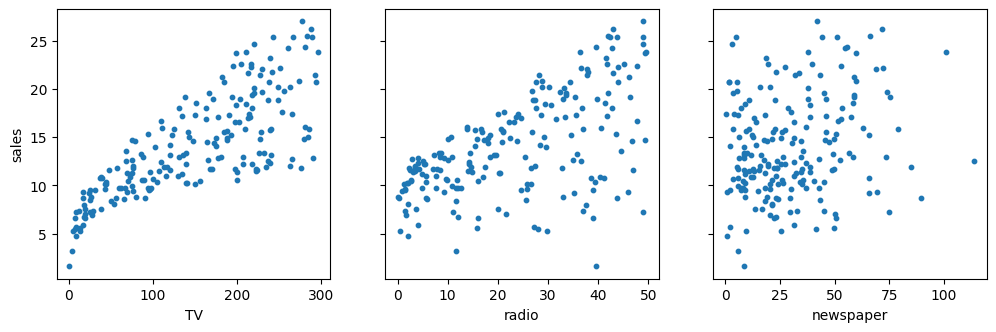

In [84]:
print(ad.head())
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, v in zip(axes, ["TV", "radio", "newspaper"]):
    ax.scatter(ad[v], ad["sales"], s=10); ax.set_xlabel(v)
axes[0].set_ylabel("sales"); plt.show()

Slide: *Multiple regression with Python* (on the slide the data are read with
`pd.read_csv("../data/Advertising.csv", index_col=0)`; here `load_data` does the same and
also works in Colab)

In [85]:
ad = load_data("Advertising.csv", index_col=0)
m3 = smf.ols("sales ~ TV + radio + newspaper", data=ad).fit()  # sales explained by ...
print(m3.summary())

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     570.3
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           1.58e-96
Time:                        15:30:35   Log-Likelihood:                -386.18
No. Observations:                 200   AIC:                             780.4
Df Residuals:                     196   BIC:                             793.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9389      0.312      9.422      0.0

### 5.2 Interpreting the coefficients

Slides: *Interpreting the coefficients -- ceteris paribus*, *Simple vs. multiple slopes*, *Confounding: why the newspaper slope collapses*

**In words:** a coefficient in a multiple regression is a *partial* effect. On its own,
newspaper looks significant; together with TV and radio its effect disappears --
newspaper acts as a proxy for radio (correlation 0.35).

In [86]:
for v in ["TV", "radio", "newspaper"]:
    m = smf.ols(f"sales ~ {v}", data=ad).fit()
    print(f"{v:10s} simple slope {m.params[v]:7.4f} (p = {m.pvalues[v]:.3f})   "
          f"multiple slope {m3.params[v]:7.4f} (p = {m3.pvalues[v]:.3f})")
print(ad.corr().round(4))                                          # corr(radio, newspaper) = 0.3541

TV         simple slope  0.0475 (p = 0.000)   multiple slope  0.0458 (p = 0.000)
radio      simple slope  0.2025 (p = 0.000)   multiple slope  0.1885 (p = 0.000)
newspaper  simple slope  0.0547 (p = 0.001)   multiple slope -0.0010 (p = 0.860)
               TV   radio  newspaper   sales
TV         1.0000  0.0548     0.0566  0.7822
radio      0.0548  1.0000     0.3541  0.5762
newspaper  0.0566  0.3541     1.0000  0.2283
sales      0.7822  0.5762     0.2283  1.0000


#### Exercise -- why newspaper "works" alone

A simple regression of sales on the newspaper budget gives a positive, significant slope
(0.0547, $p = 0.001$). In the multiple regression the newspaper coefficient is $-0.0010$ with
$p = 0.86$. The correlation between the newspaper and radio budgets is 0.35.

1. Explain how newspaper can look useful on its own but useless in the joint model.
2. Which variable is the actual driver?
3. State the general lesson for interpreting simple correlations.

In [87]:
# Your turn: compare the regressions sales ~ newspaper, sales ~ newspaper + radio, ...

**Solution**

In [88]:
print(smf.ols("sales ~ newspaper", data=ad).fit().params.round(4).tolist())           # slope 0.0547 alone
print(smf.ols("sales ~ newspaper + radio", data=ad).fit().params.round(4).tolist())   # almost 0 once radio is in
print(round(ad["newspaper"].corr(ad["radio"]), 2))                                     # 0.35
# (1) confounding: high radio budgets go with high newspaper budgets, and radio drives sales
# (2) radio (and TV); (3) a simple association can be produced by an omitted variable

[12.3514, 0.0547]
[9.1889, 0.0066, 0.199]
0.35


### 5.3 Inference for single coefficients

Slides: *$t$-test for a single coefficient*, *Confidence intervals in multiple regression*

$$T = \frac{\hat\beta_j}{\operatorname{SE}(\hat\beta_j)} \sim t_{n-p-1}, \qquad
\text{CI}_{1-\alpha}(\beta_j) = \hat\beta_j \pm t_{1-\alpha/2,\,n-p-1}\operatorname{SE}(\hat\beta_j)$$

**In words:** $H_0: \beta_j = 0$ means "$X_j$ adds nothing given the other variables";
newspaper: $T = -0.18$, keep $H_0$.

In [89]:
print(m3.tvalues.round(2).tolist(), " t_0.975;196 =", round(stats.t.ppf(0.975, df=196), 3))   # 1.972
b, se = m3.params["radio"], m3.bse["radio"]
print("radio:", round(b, 5), "+-", round(1.972 * se, 5))       # 0.18853 +- 0.01698
m3.conf_int()                                                   # radio [0.1715; 0.2055]

[9.42, 32.81, 21.89, -0.18]  t_0.975;196 = 1.972
radio: 0.18853 +- 0.01698


,0,1
Intercept,2.3238,3.5540
TV,0.0430,0.0485
radio,0.1715,0.2055
newspaper,-0.0126,0.0105


### 5.4 $F$-test

Slides: *Is any explanatory variable useful? -- the $F$-test*, *$F$-test -- advertising example*

$$H_0: \beta_1 = \cdots = \beta_p = 0, \qquad F = \frac{(\text{TSS} - \text{RSS})/p}{\text{RSS}/(n-p-1)} \sim F_{p,\,n-p-1}$$

**In words:** large $F$: the variables explain more than chance would -- reject $H_0$
(right-sided test).

In [90]:
TSS_ad = ((ad["sales"] - ad["sales"].mean())**2).sum(); RSS_ad = (m3.resid**2).sum()
print("TSS =", round(TSS_ad, 2), "  RSS =", round(RSS_ad, 2))                           # 5417.15, 556.83
print("F =", round(((TSS_ad - RSS_ad) / 3) / (RSS_ad / 196), 1),
      "  F_0.95;3,196 =", round(stats.f.ppf(0.95, 3, 196), 2))                          # 570.3 >> 2.65

TSS = 5417.15   RSS = 556.83
F = 570.3   F_0.95;3,196 = 2.65


Slide: *Why not just several $t$-tests?*

**In words:** with many variables some $t$-tests are "significant" by chance; the $F$-test
is one test for all slopes. In simple regression $F = T^2$ (lamp: $125.2 = (-11.19)^2$).

In [91]:
reg = smf.ols("quantity ~ price", data=df).fit()
print(round(reg.fvalue, 1), round(reg.tvalues["price"]**2, 1))    # 125.2  125.2

125.2 125.2


Slide: *The $F$-test with Python*

**In words:** `stats.f.sf()` is the area to the right of $F$: the $F$-test is right-sided.

In [92]:
m3 = smf.ols("sales ~ TV + radio + newspaper", data=ad).fit()
print(round(m3.fvalue, 1), f"{m3.f_pvalue:.3g}")      # 570.3  1.58e-96 ("F-statistic", "Prob (F-statistic)")

570.3 1.58e-96


In [93]:
TSS, RSS = m3.centered_tss, m3.ssr              # 5417.15  556.83
n, p = len(ad), 3                               # 200  3
F = ((TSS - RSS) / p) / (RSS / (n - p - 1))     # 570.3
print(round(TSS, 2), round(RSS, 2), n, p, round(F, 1))
print(round(stats.f.ppf(0.95, p, n - p - 1), 2))   # critical value 2.65
print(f"{stats.f.sf(F, p, n - p - 1):.3g}")        # p-value 1.58e-96

5417.15 556.83 200 3 570.3
2.65
1.58e-96


#### Exercise -- the $F$-test

A multiple regression with $p = 3$ explanatory variables is fitted on $n = 100$
observations, giving $\text{TSS} = 1000$ and $\text{RSS} = 100$.

1. Compute $R^2$ and the $F$-statistic.
2. Compare with $F_{0.95;\,3,\,96} = 2.70$. What do you conclude?
3. Suppose instead 100 explanatory variables were all truly useless. About how many would appear "significant" at $\alpha = 0.05$ in individual $t$-tests?

In [94]:
TSS, RSS, n, p = 1000, 100, 100, 3
# Your turn

**Solution**

In [95]:
TSS, RSS, n, p = 1000, 100, 100, 3
F = ((TSS - RSS) / p) / (RSS / (n - p - 1))
print("R^2 =", 1 - RSS / TSS, "  F =", round(F, 1))                  # (1) 0.9, 288.0
print("F_0.95;3,96 =", round(stats.f.ppf(0.95, 3, 96), 2))           # (2) 2.70: 288 >> 2.70, reject H0
print("expected false alarms:", 100 * 0.05)                           # (3) about 5

R^2 = 0.9   F = 288.0
F_0.95;3,96 = 2.7
expected false alarms: 5.0


### 5.5 Goodness of fit and model choice

Slides: *$R^2$ and adjusted $R^2$*, *Model choice -- dropping newspaper*

$$\bar R^2 = 1 - \frac{\text{RSS}/(n-p-1)}{\text{TSS}/(n-1)} = 1 - (1 - R^2)\frac{n-1}{n-p-1}$$

**In words:** $R^2$ never decreases when a variable is added; adjusted $R^2$ and $\hat\sigma$
penalise useless variables -- dropping newspaper raises $\bar R^2$ and lowers $\hat\sigma$.

In [96]:
print("adjusted R^2 by hand:", round(1 - (RSS_ad / 196) / (TSS_ad / 199), 5))     # 0.89564
m2 = smf.ols("sales ~ TV + radio", data=ad).fit()
for name, m in [("TV + radio + newspaper", m3), ("TV + radio", m2)]:
    print(f"{name:24s} TV {m.params['TV']:.4f}  radio {m.params['radio']:.4f}  R^2 {m.rsquared:.5f}"
          f"  adj {m.rsquared_adj:.5f}  sigma {np.sqrt(m.scale):.4f}")
print(sm.stats.anova_lm(m2, m3))       # partial F-test for newspaper: p = 0.86

adjusted R^2 by hand: 0.89564
TV + radio + newspaper   TV 0.0458  radio 0.1885  R^2 0.89721  adj 0.89564  sigma 1.6855
TV + radio               TV 0.0458  radio 0.1880  R^2 0.89719  adj 0.89615  sigma 1.6814
   df_resid       ssr  df_diff  ss_diff       F  Pr(>F)
0     197.0  556.9140      0.0      NaN     NaN     NaN
1     196.0  556.8253      1.0   0.0887  0.0312  0.8599


Slide: *Prediction in multiple regression*

$\hat y_0 = 2.921 + 0.04575\cdot 100 + 0.18799\cdot 20 = 11.26$; CI $[10.99; 11.53]$, PI $[7.93; 14.58]$.

**In words:** with $n = 200$ the mean is estimated precisely, but a single market still
varies by about $\pm 2\hat\sigma$.

In [97]:
m2.get_prediction(pd.DataFrame({"TV": [100], "radio": [20]})).summary_frame(alpha=0.05).round(2)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,11.26,0.14,10.99,11.53,7.93,14.58


### 5.6 Qualitative explanatory variables

Slides: *What if an explanatory variable is categorical?*, *A dummy shifts the intercept*, *$K$ categories: use $K-1$ dummies*

$$D_i = \begin{cases} 1 & \text{student} \\ 0 & \text{otherwise (baseline)}\end{cases}, \qquad
\widehat{\texttt{Balance}} = 480.37 + 396.46\,D$$

**In words:** the coefficient of a dummy is the difference to the baseline group; a variable
with $K$ categories needs $K-1$ dummies (dummy variable trap).

Slide: *Dummy variables with Python* (`load_data` replaces `pd.read_csv("../data/Credit.csv")`)

In [98]:
cr = load_data("Credit.csv")
print(smf.ols("Balance ~ Student", data=cr).fit().params)
# Intercept 480.37, Student[T.Yes] 396.46
print(cr.groupby("Student")["Balance"].mean())     # No 480.37, Yes 876.825

Intercept         480.3694
Student[T.Yes]    396.4556
dtype: float64
Student
No     480.3694
Yes    876.8250
Name: Balance, dtype: float64


In [99]:
print(smf.ols("Balance ~ Income + Student", data=cr).fit().params)
# Intercept 211.14, Student[T.Yes] 382.67, Income 5.98
print(smf.ols("Balance ~ Region", data=cr).fit().params)
# Intercept 531.00, Region[T.South] -12.50, Region[T.West] -18.69

Intercept         211.1430
Student[T.Yes]    382.6705
Income              5.9843
dtype: float64


Intercept          531.0000
Region[T.South]    -12.5025
Region[T.West]     -18.6863
dtype: float64


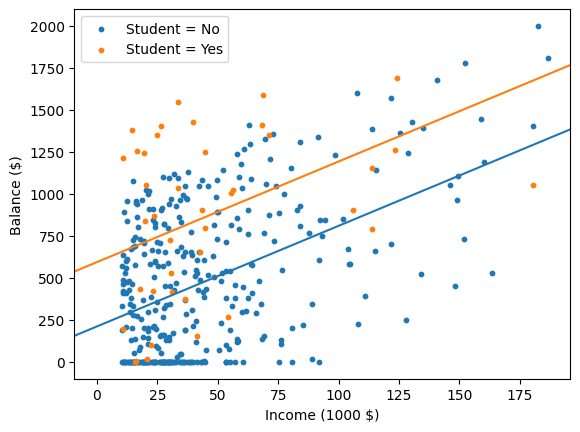

In [100]:
# Slide "A dummy shifts the intercept": two parallel lines
md_inc = smf.ols("Balance ~ Income + Student", data=cr).fit()
a, bi, bs = md_inc.params["Intercept"], md_inc.params["Income"], md_inc.params["Student[T.Yes]"]
for lev, shift, col in [("No", 0, "tab:blue"), ("Yes", bs, "tab:orange")]:
    d = cr[cr["Student"] == lev]
    plt.scatter(d["Income"], d["Balance"], s=10, color=col, label=f"Student = {lev}")
    plt.axline((0, a + shift), slope=bi, color=col)
plt.xlabel("Income (1000 $)"); plt.ylabel("Balance ($)"); plt.legend(); plt.show()

#### Exercise -- dummy coding

1. From $\widehat{\texttt{Balance}} = 480.37 + 396.46\,D_{\text{Student}}$, give the predicted mean balance of students and of non-students. Interpret 396.46.
2. From $\widehat{\texttt{Balance}} = 531.00 - 12.50\,D_{\text{South}} - 18.69\,D_{\text{West}}$ (baseline East), give the predicted mean balance in each region. How large is the difference between South and West?
3. Why are only $K-1$ dummies used for a variable with $K$ categories?

In [101]:
# Your turn (the data frame cr is loaded above)

**Solution**

In [102]:
print("non-students:", 480.37, "  students:", round(480.37 + 396.46, 2))      # (1) 876.83: difference in means
print("East:", 531.00, " South:", round(531.00 - 12.50, 2), " West:", round(531.00 - 18.69, 2),
      " South - West:", round(-12.50 - (-18.69), 2))                           # (2) 518.5, 512.31, +6.19
print(cr.groupby("Region")["Balance"].mean().round(2))                         # the group means directly
# (3) K dummies plus intercept: the dummies add up to the intercept column (dummy variable trap)

non-students: 480.37   students: 876.83
East: 531.0  South: 518.5  West: 512.31  South - West: 6.19
Region
East     531.00
South    518.50
West     512.31
Name: Balance, dtype: float64


### 5.7 Exercise: reading a full output

#### Exercise -- reading a multiple regression output

Credit data ($n = 400$): balance (\$) explained by income (1000 \$), credit limit (\$) and
student status: `mc = smf.ols("Balance ~ Income + Limit + Student", data=cr).fit()`.

1. Interpret the coefficients of `Limit` and `Student[T.Yes]`.
2. Compute the 95 % CI for the income coefficient by hand ($t_{0.975;\,396} = 1.966$, unrounded `std err` 0.2432) and compare it with the columns `[0.025 0.975]`.
3. Alone, `Balance ~ Income` has slope $+6.05$. Why is it negative here? ($r(\text{Income}, \text{Limit}) = 0.79$.)
4. What do the $F$-test and $R^2$ say? Predict the balance of a non-student with income 50 and limit 5000.

In [103]:
mc = smf.ols("Balance ~ Income + Limit + Student", data=cr).fit()
# Your turn: print(mc.summary()) and answer the questions

**Solution**

In [104]:
mc = smf.ols("Balance ~ Income + Limit + Student", data=cr).fit()
print(mc.summary().tables[1])                  # (1) Limit 0.2675 per $, students +427 $ (holding the others fixed)
b, se = mc.params["Income"], mc.bse["Income"]
print("CI by hand:", round(b - 1.966 * se, 3), round(b + 1.966 * se, 3))     # (2) [-8.380; -7.424]
print("alone:", round(smf.ols("Balance ~ Income", data=cr).fit().params["Income"], 2),
      "  corr(Income, Limit) =", round(cr["Income"].corr(cr["Limit"]), 2))   # (3) +6.05, 0.79: confounding
print("F =", round(mc.fvalue, 1), " p =", f"{mc.f_pvalue:.3g}", " R^2 =", round(mc.rsquared, 4),
      " adj =", round(mc.rsquared_adj, 4))                                 # (4) 2446.8, 4e-255, 0.9488, 0.9484
new = pd.DataFrame({"Income": 50, "Limit": 5000, "Student": ["No", "Yes"]})
print(mc.get_prediction(new).summary_frame(alpha=0.05).round(1))           # 510.3, PI [304.7; 715.8]; student 937.3

                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept       -432.3374     12.431    -34.778      0.000    -456.777    -407.898
Student[T.Yes]   427.0233     17.416     24.519      0.000     392.784     461.263
Income            -7.9016      0.243    -32.495      0.000      -8.380      -7.424
Limit              0.2675      0.004     72.069      0.000       0.260       0.275
CI by hand: -8.38 -7.424


alone: 6.05   corr(Income, Limit) = 0.79
F = 2446.8  p = 4e-255  R^2 = 0.9488  adj = 0.9484
    mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  510.3      5.6          499.4          521.2         304.7         715.8
1  937.3     16.5          904.8          969.8         729.5        1145.1


Slide: *Multiple regression with Python -- overview*

In [105]:
m3 = smf.ols("sales ~ TV + radio + newspaper", data=ad).fit()
print(m3.summary())         # t-tests, R^2, adjusted R^2, F-test
m3.conf_int()               # confidence intervals

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     570.3
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           1.58e-96
Time:                        15:30:35   Log-Likelihood:                -386.18
No. Observations:                 200   AIC:                             780.4
Df Residuals:                     196   BIC:                             793.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9389      0.312      9.422      0.0

,0,1
Intercept,2.3238,3.5540
TV,0.0430,0.0485
radio,0.1715,0.2055
newspaper,-0.0126,0.0105


   df_resid       ssr  df_diff  ss_diff       F  Pr(>F)
0     197.0  556.9140      0.0      NaN     NaN     NaN
1     196.0  556.8253      1.0   0.0887  0.0312  0.8599
Intercept         211.1430
Student[T.Yes]    382.6705
Income              5.9843
dtype: float64
    mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  11.26     0.14          10.99          11.53          7.93         14.58


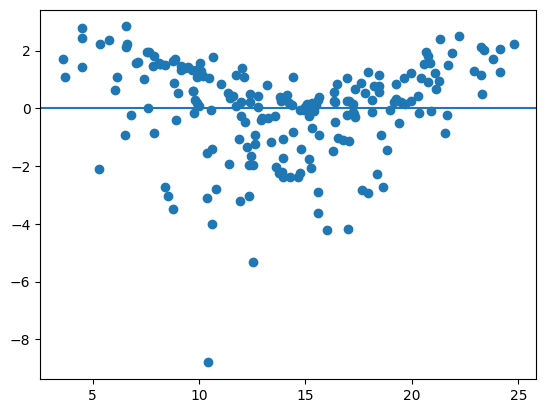

In [106]:
m2 = smf.ols("sales ~ TV + radio", data=ad).fit()
print(sm.stats.anova_lm(m2, m3))   # F-test: does newspaper add anything? (p = 0.86)
print(smf.ols("Balance ~ Income + Student", data=cr).fit().params)  # text -> dummy Student[T.Yes]
new = pd.DataFrame({"TV": [100], "radio": [20]})
print(m2.get_prediction(new).summary_frame().round(2))      # obs_ci_*: prediction interval
plt.scatter(m2.fittedvalues, m2.resid); plt.axhline(0)      # residual plot
plt.show()

## 6 Summary

Slides: *Summary 1--3*, *Five classic pitfalls -- final checklist*

| Quantity | Formula |
|---|---|
| Covariance | $s_{xy} = \frac{1}{n-1}\sum (x_i-\bar x)(y_i-\bar y)$ |
| Correlation | $r_{xy} = s_{xy}/(s_x s_y)$ |
| Least squares | $\min \sum (y_i - \beta_0 - \beta_1 x_i)^2$, first-order conditions $\sum\hat u_i = 0$, $\sum x_i\hat u_i = 0$ |
| Slope, intercept | $\hat\beta_1 = s_{xy}/s_x^2 = S_{xy}/S_{xx}$, $\hat\beta_0 = \bar y - \hat\beta_1\bar x$ |
| Coefficient of determination | $R^2 = \text{ESS}/\text{TSS} = 1 - \text{RSS}/\text{TSS}$ ($= r_{xy}^2$ in simple regression) |
| Residual standard error | $\hat\sigma = \sqrt{\text{RSS}/(n-p-1)}$ |
| $t$-test, CI | $T = (\hat\beta_j - \beta_{j,0})/\operatorname{SE}(\hat\beta_j) \sim t_{n-p-1}$, $\hat\beta_j \pm t_{1-\alpha/2,\,n-p-1}\operatorname{SE}(\hat\beta_j)$ |
| Prediction at $x_0$ | $\hat y_0 \pm t_{1-\alpha/2,\,n-2}\,\hat\sigma\sqrt{1 + 1/n + (x_0-\bar x)^2/S_{xx}}$ (without the $1$: CI for the mean) |
| $F$-test | $F = \frac{(\text{TSS}-\text{RSS})/p}{\text{RSS}/(n-p-1)}$ |
| Adjusted $R^2$ | $\bar R^2 = 1 - \frac{\text{RSS}/(n-p-1)}{\text{TSS}/(n-1)}$ |

**Pitfalls:** correlation is not causation; a high $R^2$ does not make the model correct;
"not significant" is not "no effect"; a multiple-regression coefficient holds the other
variables fixed; no extrapolation far beyond the observed $x$-range.

In [107]:
# The lamp example in a nutshell: estimate, fit, inference and prediction
reg = smf.ols("quantity ~ price", data=df).fit()
print(reg.params.round(4).tolist(), round(reg.rsquared, 4), round(np.sqrt(reg.scale), 4))   # 54.6667 -0.4467, 0.947, 1.5461
print(reg.conf_int().round(4))
print(reg.get_prediction(pd.DataFrame({"price": [110]})).summary_frame(alpha=0.05).round(2))

[54.6667, -0.4467] 0.947 1.5461
                 0        1
Intercept  45.1486  64.1847
price      -0.5411  -0.3523
   mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  5.53     0.65           3.99           7.07          1.57           9.5


## Appendix: Optional and Advanced Material

### A.1 Derivation of the OLS estimators

Slides: *Appendix: derivation (1/7)--(7/7)*

$$\frac{\partial S}{\partial\beta_0} = -2\sum (y_i - \beta_0 - \beta_1 x_i) = 0, \qquad
\frac{\partial S}{\partial\beta_1} = -2\sum x_i (y_i - \beta_0 - \beta_1 x_i) = 0$$

Normal equations: (I) $\sum y_i = n\beta_0 + \beta_1\sum x_i$, (II) $\sum x_i y_i = \beta_0\sum x_i + \beta_1 \sum x_i^2$;
second-order condition $4n\,S_{xx} > 0$.

**In words:** set both partial derivatives to zero, solve (I) for $\beta_0$, insert into (II).
Near the solution the sum of squares is larger in every direction -- a bowl with one minimum.

In [108]:
x, y = shop["adv"], shop["revenue"]
for b0, b1 in [(20, 2), (20.5, 2), (20, 2.1), (19, 2.3)]:
    print(f"S({b0}, {b1}) = {((y - b0 - b1 * x)**2).sum():.2f}")     # 14 at the OLS solution, larger elsewhere

S(20, 2) = 14.00
S(20.5, 2) = 15.25
S(20, 2.1) = 14.55
S(19, 2.3) = 14.95


#### Exercise -- online shop (A): solving the normal equations

Sums of the online shop: $n = 5$, $\sum x_i = 15$, $\sum y_i = 130$, $\sum x_i^2 = 55$, $\sum x_i y_i = 410$.

1. Write down both normal equations with these sums.
2. Solve the system of equations for $\beta_0$ and $\beta_1$.
3. Compare the result with exercise (5).

In [109]:
x, y = shop["adv"], shop["revenue"]
# Your turn: sums, normal equations I and II, solve them

**Solution**

In [110]:
x, y = shop["adv"], shop["revenue"]
print(len(x), x.sum(), y.sum(), (x**2).sum(), (x * y).sum())   # (1) 5 15 130 55 410
# I: 130 = 5 b0 + 15 b1,  II: 410 = 15 b0 + 55 b1
A = [[5, 15], [15, 55]]           # coefficients of beta0, beta1 in I and II
np.linalg.solve(A, [130, 410])    # (2) array([20., 2.]): beta0 = 20, beta1 = 2 -- (3) the line of exercise (5)

5 15 130 55 410


array([20.,  2.])

### A.2 Minimum property of OLS

Slide: *Why no other line beats the OLS line*

With $a = \beta_0 - \hat\beta_0$, $b = \beta_1 - \hat\beta_1$:
$$S(\beta_0, \beta_1) = \text{RSS} + n\,(a + b\bar x)^2 + b^2 S_{xx}$$

**In words:** every other line pays two penalties -- for missing the centroid and for the
wrong slope.

In [111]:
x, y = stores["adv"], stores["revenue"]
for name in ("A", "B", "C"):
    a, b = lines[name][0] - 30, lines[name][1] - 1.2
    S_formula = 64.8 + 12 * (a + b * x.mean())**2 + b**2 * 155
    S_direct = ((y - lines[name][0] - lines[name][1] * x)**2).sum()
    print(f"line {name}: a = {a:.1f}, b = {b:.1f}, S = {S_formula:.1f} (direct: {S_direct:.1f})")   # 164.0, 120.6, 364.8

line A: a = -6.0, b = 0.8, S = 164.0 (direct: 164.0)
line B: a = 4.5, b = -0.6, S = 120.6 (direct: 120.6)
line C: a = 5.0, b = 0.0, S = 364.8 (direct: 364.8)


### A.3 Residual analysis

Slides: *Roadmap*, *A line can always be computed -- but does it fit?*, *What happens if an assumption is violated?*, *From the scatter plot to the residual plot*, *The residual plot*

Residual plot: points $(\hat y_i, \hat u_i)$ with the zero line.

**In words:** ideal is a structureless band of constant width around the zero line; the
twelve stores show no arc, no funnel and no outlier.

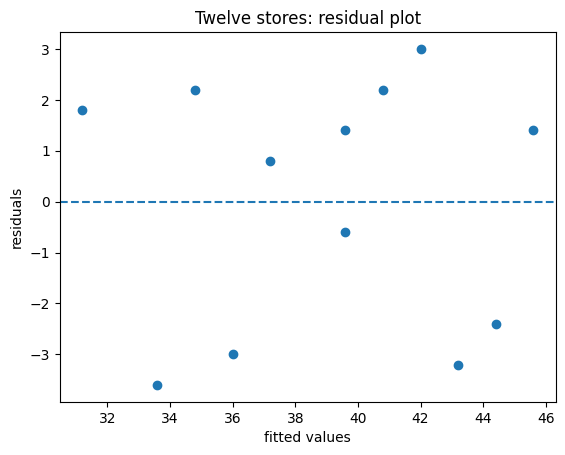

store 9: 42.0 3.0   largest |residual|: 3.6


In [112]:
reg12 = smf.ols("revenue ~ adv", data=stores).fit()
plt.scatter(reg12.fittedvalues, reg12.resid); plt.axhline(0, linestyle="--")
plt.xlabel("fitted values"); plt.ylabel("residuals"); plt.title("Twelve stores: residual plot"); plt.show()
print("store 9:", round(reg12.fittedvalues[8], 4), round(reg12.resid[8], 4), "  largest |residual|:", round(reg12.resid.abs().max(), 2))   # (42, 3), 3.6

#### Exercise -- online shop (B): draw the residual plot

Online shop with the OLS line $\hat y = 20 + 2x$.

1. Compute the fitted values $\hat y_i$.
2. Compute the residuals $\hat u_i$; check their sum.
3. Draw the residual plot.
4. Judge: is there a pattern?

In [113]:
x, y = shop["adv"], shop["revenue"]
# Your turn

**Solution**

fitted: [22, 24, 26, 28, 30]   residuals: [-1, 2, -2, 2, -1]   sum: 0


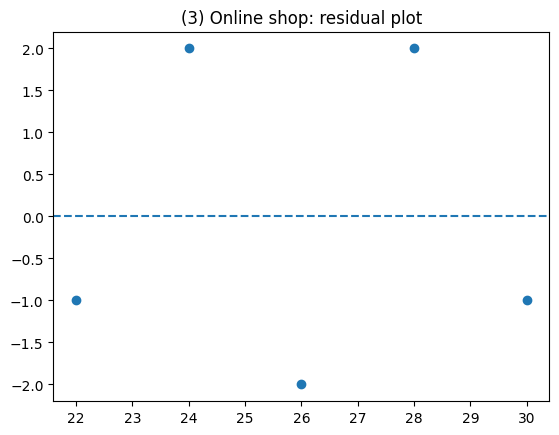

In [114]:
x, y = shop["adv"], shop["revenue"]
yhat = 20 + 2 * x; u = y - yhat
print("fitted:", yhat.tolist(), "  residuals:", u.tolist(), "  sum:", u.sum())   # (1), (2) 22..30; -1 2 -2 2 -1; 0
plt.scatter(yhat, u); plt.axhline(0, linestyle="--"); plt.title("(3) Online shop: residual plot"); plt.show()
# (4) no arc, no funnel; with five values no reliable pattern

Slides: *Four typical patterns in the residual plot*, *Interpreting patterns*, *Back to the saturation example*, *Lamp example: assessing the residual plot*

Arc $\to$ wrong functional form ($E(u_i) = 0$ violated); funnel $\to$ heteroscedasticity;
waves $\to$ autocorrelation.

**In words:** the saturation example shows a clear arc despite $R^2 = 0.81$; the lamp shows
no clear pattern, only one conspicuous residual at 95 euros.

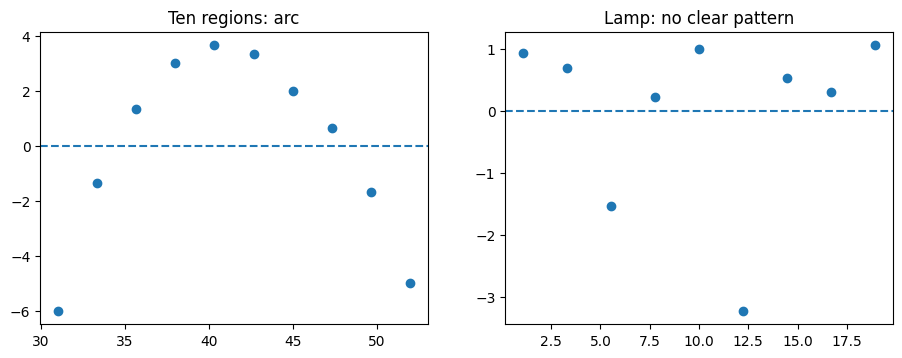

lamp, price 95: fitted 12.23  residual -3.23


In [115]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(reg_sat.fittedvalues, reg_sat.resid); axes[0].axhline(0, ls="--"); axes[0].set_title("Ten regions: arc")
reg = smf.ols("quantity ~ price", data=df).fit()
axes[1].scatter(reg.fittedvalues, reg.resid); axes[1].axhline(0, ls="--"); axes[1].set_title("Lamp: no clear pattern")
plt.show()
print("lamp, price 95: fitted", round(reg.fittedvalues[3], 2), " residual", round(reg.resid[3], 2))   # 12.23, -3.23

Slide: *Creating a residual plot with Python*

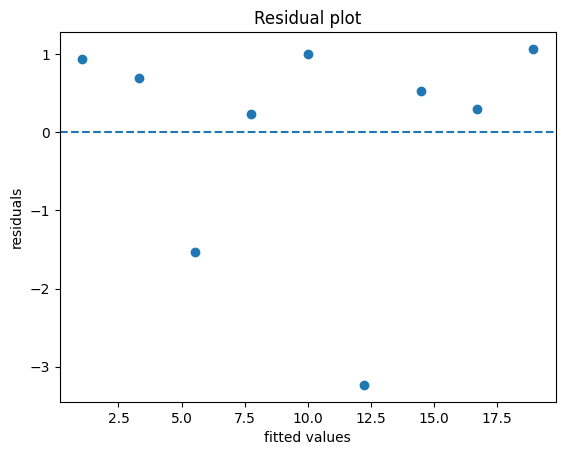

3.552713678800501e-14


In [116]:
reg = smf.ols("quantity ~ price", data=df).fit()
plt.scatter(reg.fittedvalues, reg.resid)
plt.axhline(0, linestyle="--")      # zero line for orientation
plt.xlabel("fitted values"); plt.ylabel("residuals"); plt.title("Residual plot")
plt.show()
print(reg.resid.sum())              # practically 0 (rounding): first-order condition

#### Exercise -- diagnosing residual plots

Three regressions ($n = 25$ each): **(A)** monthly rent on floor space; **(B)** daily
revenue of a café on outside temperature; **(C)** production costs on number of units.
The residual plots of the slide are entered below as (fitted value, residual) pairs.

1. Which pattern does each residual plot show?
2. Which assumption on $u_i$ is violated -- if any? Give a reason.
3. What does this mean for the OLS line, and what should be done?

In [117]:
fitted = np.round(np.linspace(0.30, 9.70, 25), 2)       # the same x-positions in all three plots
resid = {
    "A": [0.05, -0.41, 0.35, 0.57, -1.48, -1.16, 0.11, -0.38, -0.04, -1.19, 1.30, 1.24, 0.10,
          2.09, 0.91, -1.85, 0.81, -2.30, 2.18, -0.15, -0.53, -1.98, 3.65, -0.50, -1.41],
    "B": [-3.08, -1.98, -1.41, -0.80, -0.27, 0.96, 0.21, 0.50, 0.64, 1.50, 1.88, 1.42, 1.12,
          1.10, 1.67, 1.56, 1.25, 0.43, 0.50, 0.05, -0.36, -0.59, -1.48, -1.91, -2.89],
    "C": [0.38, 0.68, -1.19, -0.17, -0.31, -0.46, -0.13, 1.46, -0.66, 0.99, -1.40, -0.18, 0.26,
          0.64, 0.76, 0.83, -0.20, -0.30, 0.89, -0.06, -1.03, -0.90, -0.71, 0.56, 0.24]}
# Your turn: draw the three residual plots and diagnose them

**Solution**

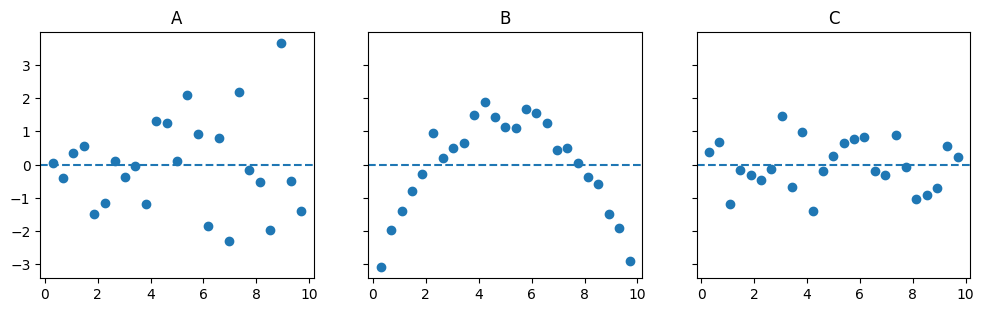

A: mean residual per third [-0.27, 0.43, -0.13], spread left/right half [0.83, 1.8]
B: mean residual per third [-0.58, 1.44, -0.78], spread left/right half [1.43, 1.39]
C: mean residual per third [-0.04, 0.21, -0.16], spread left/right half [0.78, 0.66]


In [118]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, (name, u) in zip(axes, resid.items()):
    ax.scatter(fitted, u); ax.axhline(0, ls="--"); ax.set_title(name)
plt.show()
for name, u in resid.items():
    u = np.array(u)
    thirds = [round(float(part.mean()), 2) for part in np.array_split(u, 3)]
    halves = [round(float(part.std()), 2) for part in np.array_split(u, 2)]
    print(f"{name}: mean residual per third {thirds}, spread left/right half {halves}")
# (A) funnel: spread grows (0.83 -> 1.80) -> heteroscedasticity: SEs and tests unreliable (log y, robust SEs)
# (B) arc: -, +, - -> E(u_i) = 0 violated, not linear: estimates biased (add a quadratic term)
# (C) random band -> no assumption recognisably violated: the line is adequate

### A.4 Outliers and leverage

Slides: *Outliers and leverage values*, *Leverage values -- rule of thumb*, *Leverage values -- lamp example*

$$h_i = \frac1n + \frac{(x_i - \bar x)^2}{\sum_j (x_j - \bar x)^2}, \qquad \frac1n \le h_i \le 1, \qquad
\text{flag if } h_i > \frac4n \ \Bigl(\text{small samples: } \frac6n\Bigr)$$

**In words:** the further $x_i$ lies from $\bar x$, the longer the lever arm -- inspect a
flagged point and compare the fit with and without it; do not delete it automatically.

Slide: *Leverage values with Python*

In [119]:
reg = smf.ols("quantity ~ price", data=df).fit()
h = reg.get_influence().hat_matrix_diag   # leverage value h_i of every store
print(h.round(3))      # 0.378 0.261 0.178 0.128 0.111 0.128 0.178 0.261 0.378
n = len(df); print(round(4 / n, 3))       # threshold 0.444
print((h > 4 / n).sum())                  # 0: no store is flagged

[0.378 0.261 0.178 0.128 0.111 0.128 0.178 0.261 0.378]
0.444
0


In [120]:
x = df["price"]
print((1 / n + (x - x.mean())**2 / ((x - x.mean())**2).sum()).round(3).tolist())   # the same h_i
print(round(smf.ols("quantity ~ price", data=df[df["price"] != 95]).fit().params["price"], 4))
# -0.4590: slope without the store at 95 EUR (with it: -0.4467)
print(round(smf.ols("quantity ~ price", data=df[df["price"] != 80]).fit().params["price"], 4))
# -0.4238: without the store at 80 EUR (largest leverage)

[0.378, 0.261, 0.178, 0.128, 0.111, 0.128, 0.178, 0.261, 0.378]
-0.459
-0.4238


#### Exercise -- online shop (C): a month with a big campaign

The online shop records three more months. In month 8 it runs a big campaign (advertising
$x_i$ in 1000 EUR):

| Month $i$ | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|---|
| Advertising $x_i$ | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 20 |

1. Compute $\bar x$ and $S_{xx} = \sum (x_i - \bar x)^2$.
2. Compute the leverage values $h_1$, $h_6$ and $h_8$.
3. Which of these months are flagged by the rule of thumb ($4/n$; small samples $6/n$)?
4. Why are the revenues $y_i$ not needed for this? What should the shop do with a flagged month?

In [121]:
x8 = pd.Series([1, 2, 3, 4, 5, 6, 7, 20])
# Your turn

**Solution**

In [122]:
n8 = len(x8); Sxx8 = ((x8 - x8.mean())**2).sum()
print("xbar =", x8.mean(), "  S_xx =", Sxx8)                       # (1) 6.0, 252.0
h8 = 1 / n8 + (x8 - x8.mean())**2 / Sxx8
print("h_1, h_6, h_8 =", round(h8[0], 4), round(h8[5], 4), round(h8[7], 4))   # (2) 0.2242, 0.125, 0.9028
print("4/n =", 4 / n8, "  6/n =", 6 / n8, "  flagged months:", (h8[h8 > 6 / n8].index + 1).tolist())  # (3) month 8
# (4) h_i depends only on the x-values; inspect month 8 and compare the fit with and without it

xbar = 6.0   S_xx = 252.0
h_1, h_6, h_8 = 0.2242 0.125 0.9028
4/n = 0.5   6/n = 0.75   flagged months: [8]


### A.5 QQ-plot

Slides: *Is the error term normally distributed? The QQ-plot*, *The idea: plot quantiles against each other*, *Warm-up: prices and quantities of the lamp*, *QQ-plot: prices against quantities*

Sort each variable on its own and plot the pairs $(x_{(i)}, y_{(i)})$; reference line through
the pairs of 25 % and 75 % quantiles.

**In words:** points on a straight line mean the same distribution shape; here the pairs are
deliberately broken up.

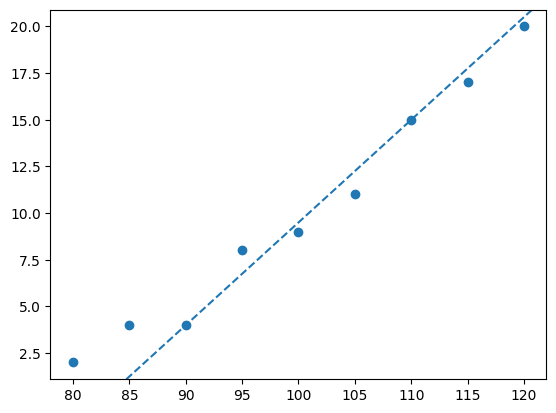

quartiles: [ 90. 110.] [ 4. 15.]   line: y = -45.5 + 0.55 x


In [123]:
x, y = np.sort(df["price"]), np.sort(df["quantity"])   # empirical quantiles
qx, qy = np.percentile(x, [25, 75]), np.percentile(y, [25, 75])
plt.scatter(x, y); plt.axline((qx[0], qy[0]), (qx[1], qy[1]), ls="--")  # slope 0.55
plt.show()
slope = (qy[1] - qy[0]) / (qx[1] - qx[0])
print("quartiles:", qx, qy, "  line: y =", round(qy[0] - slope * qx[0], 4), "+", round(slope, 4), "x")   # -45.5 + 0.55 x

Slide: *Residuals against the normal distribution: theoretical quantiles*

$$p_i = \frac{i - 0.5}{n}, \qquad z_i = \Phi^{-1}(p_i)$$

**In words:** $z_i$ is where the $i$-th smallest of $n$ values "should" lie under a normal
distribution; for $n = 5$: $-1.28, -0.52, 0, 0.52, 1.28$.

In [124]:
print(stats.norm.ppf([0.2, 0.4, 0.6, 0.8]).round(4))           # strip boundaries for n = 5
print(stats.norm.ppf((np.arange(1, 6) - 0.5) / 5).round(4))    # z_i for n = 5

[-0.8416 -0.2533  0.2533  0.8416]
[-1.2816 -0.5244  0.      0.5244  1.2816]


Slides: *Lamp example: computing the quantiles*, *Lamp example: QQ-plot of the residuals*

**In words:** in the middle the points lie close to the line; the two smallest residuals
(95 and 110 euros) lie clearly below it -- a hint at a long lower tail, but $n = 9$ is very
few data.

   u_sorted  price       p       z
1   -3.2333     95  0.0556 -1.5932
2   -1.5333    110  0.1667 -0.9674
3    0.2333    105  0.2778 -0.5895
4    0.3000     85  0.3889 -0.2822
5    0.5333     90  0.5000  0.0000
6    0.7000    115  0.6111  0.2822
7    0.9333    120  0.7222  0.5895
8    1.0000    100  0.8333  0.9674
9    1.0667     80  0.9444  1.5932


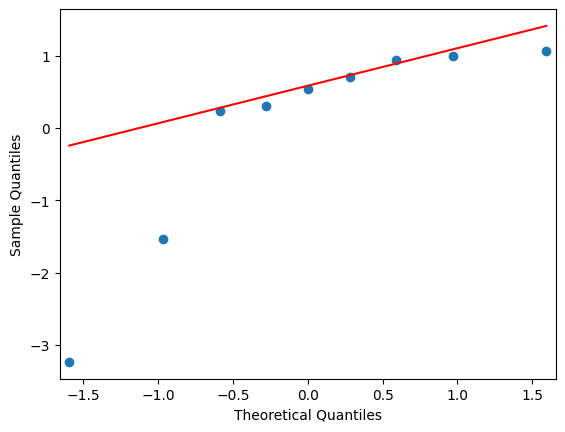

In [125]:
reg = smf.ols("quantity ~ price", data=df).fit()
order = np.argsort(reg.resid.to_numpy(), kind="stable")
p9 = (np.arange(1, 10) - 0.5) / 9
print(pd.DataFrame({"u_sorted": np.sort(reg.resid.to_numpy()).round(4), "price": df["price"].to_numpy()[order],
                    "p": p9.round(4), "z": stats.norm.ppf(p9).round(4)}, index=range(1, 10)))
sm.qqplot(reg.resid, line="q", a=0.5); plt.show()        # reference line 0.5833 + 0.5189 z

#### Exercise -- a QQ-plot by hand

Age $x$ (years) and annual maintenance costs $y$ (in 100 EUR) of $n = 5$ machines; given
$\bar x = 3$, $\bar y = 27$, $S_{xx} = 10$, $S_{xy} = 60$.

| Age $x_i$ | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| Maintenance costs $y_i$ | 17 | 21 | 25 | 29 | 43 |

1. Compute $\hat\beta_1$, $\hat\beta_0$ and all residuals; check their sum.
2. Sort the residuals and compute the plotting positions $p_i = (i - 0.5)/n$ and the normal quantiles $z_i = \Phi^{-1}(p_i)$.
3. Draw the QQ-plot and judge it.
4. Which Python command draws the QQ-plot of the residuals of a fitted model `reg`?

In [126]:
mc5 = pd.DataFrame({"age": [1, 2, 3, 4, 5], "cost": [17, 21, 25, 29, 43]})
# Your turn

**Solution**

[9.0, 6.0]
fitted: [15.0, 21.0, 27.0, 33.0, 39.0]  residuals: [2.0, 0.0, -2.0, -4.0, 4.0]  sum: 0.0
sorted: [-4.0, -2.0, 0.0, 2.0, 4.0]  p: [0.1, 0.3, 0.5, 0.7, 0.9]  z: [-1.28, -0.52, 0.0, 0.52, 1.28]


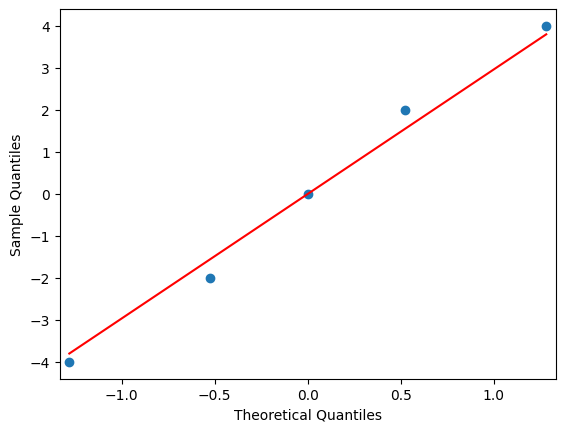

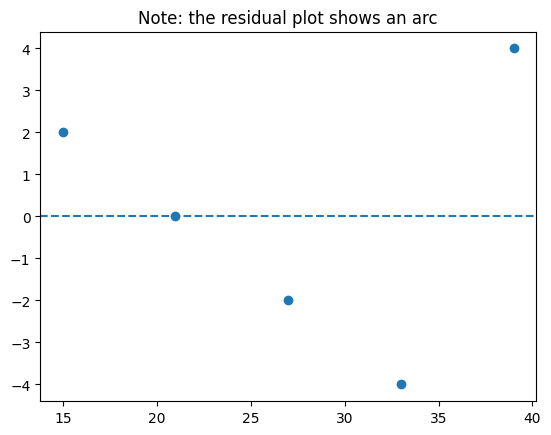

In [127]:
reg_mc5 = smf.ols("cost ~ age", data=mc5).fit()
print(reg_mc5.params.round(4).tolist())                                # (1) 9.0, 6.0 -> yhat = 9 + 6x
print("fitted:", reg_mc5.fittedvalues.round(4).tolist(), " residuals:", reg_mc5.resid.round(4).tolist(),
      " sum:", round(abs(reg_mc5.resid.sum()), 4))                     # 15..39; 2 0 -2 -4 4; 0
p5 = (np.arange(1, 6) - 0.5) / 5
print("sorted:", np.sort(reg_mc5.resid).round(4).tolist(), " p:", p5.tolist(),
      " z:", stats.norm.ppf(p5).round(2).tolist())                     # (2)
sm.qqplot(reg_mc5.resid, line="q", a=0.5); plt.show()                  # (3), (4): roughly on the line
plt.scatter(reg_mc5.fittedvalues, reg_mc5.resid); plt.axhline(0, ls="--")
plt.title("Note: the residual plot shows an arc"); plt.show()

Slide: *Typical deviations in the QQ-plot*

**In words:** an S-shape means heavy tails (more extreme values), an arc means a skewed
distribution; small deviations at the ends are normal for small $n$. (Simulated samples.)

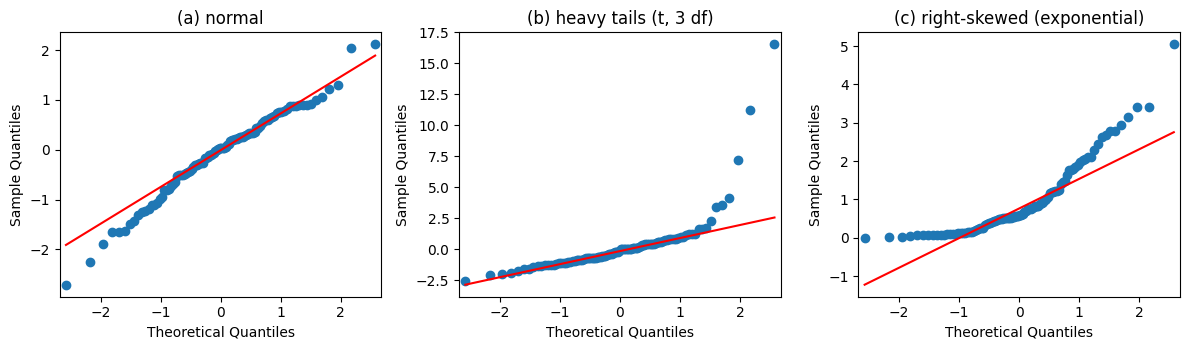

In [128]:
rng = np.random.default_rng(1)
samples = {"(a) normal": rng.normal(size=100), "(b) heavy tails (t, 3 df)": rng.standard_t(3, size=100),
           "(c) right-skewed (exponential)": rng.exponential(size=100)}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (title, sample) in zip(axes, samples.items()):
    sm.qqplot(sample, line="q", a=0.5, ax=ax); ax.set_title(title)
plt.tight_layout(); plt.show()

Slide: *QQ-plots with Python*

`sm.qqplot()` uses $p_i = (i - 0.5)/n$ (`a=0.5`; default $i/(n+1)$) and plots
$(z_i, \hat u_{(i)})$; `line="q"`: reference line through the (interpolated) quartiles.

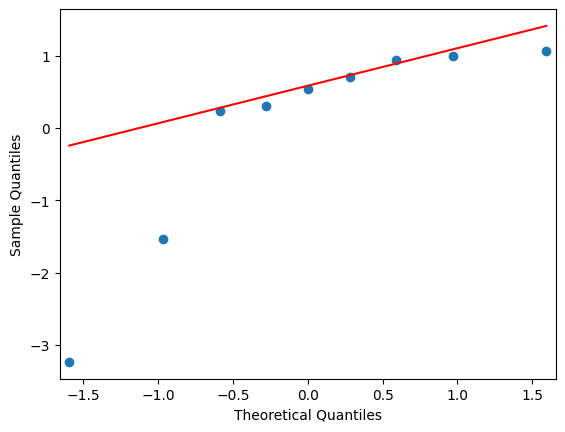

array([-1.5932, -0.9674, -0.5895, -0.2822,  0.    ,  0.2822,  0.5895,
        0.9674,  1.5932])

In [129]:
import statsmodels.api as sm; from scipy import stats
sm.qqplot(reg.resid, line="q", a=0.5)   # QQ-plot with line through quartiles
plt.show()
u = np.sort(reg.resid)                  # sorted residuals
p = (np.arange(1, 10) - 0.5) / 9        # plotting positions (i - 0.5)/n
z = stats.norm.ppf(p)                   # -1.5932, -0.9674, ..., 1.5932
z

#### Exercise -- body heights and shoe sizes: residual plot and QQ-plot

Body heights $k_i$ (cm) and shoe sizes $s_i$ of $n = 15$ persons (data `ks` of Section 3.4),
OLS line $\hat s = 2.3147 + 0.2222k$.

1. Compute the fitted values $\hat s_i$ and the residuals $\hat u_i = s_i - \hat s_i$; draw the residual plot and judge it.
2. Sort the residuals; compute the plotting positions $p_i = (i - 0.5)/n$ and the normal quantiles $z_i = \Phi^{-1}(p_i)$.
3. Draw the QQ-plot of the residuals and judge it.

In [130]:
reg_ks = smf.ols("s ~ k", data=ks).fit()       # data ks from Section 3.4
# Your turn

**Solution**

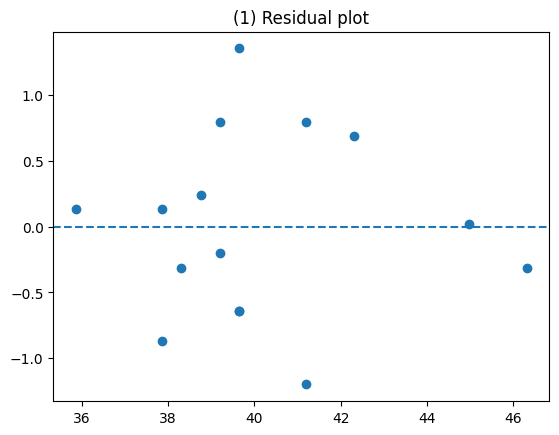

residuals from -1.2 (person 14) to 1.36 (person 13)
    u_sorted  person       p       z
1    -1.1999      14  0.0333 -1.8339
2    -0.8669       8  0.1000 -1.2816
3    -0.6445       3  0.1667 -0.9674
4    -0.6445      15  0.2333 -0.7279
5    -0.3113       2  0.3000 -0.5244
6    -0.3105       4  0.3667 -0.3407
7    -0.2001       6  0.4333 -0.1679
8     0.0227       7  0.5000  0.0000
9     0.1329       9  0.5667  0.1679
10    0.1331      12  0.6333  0.3407
11    0.2443       1  0.7000  0.5244
12    0.6891      11  0.7667  0.7279
13    0.7999       5  0.8333  0.9674
14    0.8001      10  0.9000  1.2816
15    1.3555      13  0.9667  1.8339


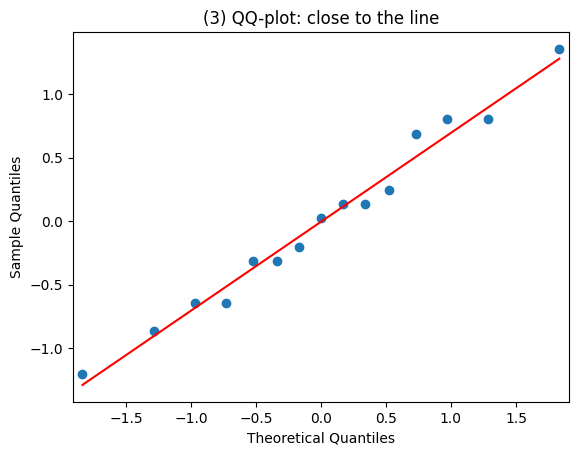

In [131]:
reg_ks = smf.ols("s ~ k", data=ks).fit()
plt.scatter(reg_ks.fittedvalues, reg_ks.resid); plt.axhline(0, ls="--"); plt.title("(1) Residual plot"); plt.show()
print("residuals from", round(reg_ks.resid.min(), 2), "(person 14) to", round(reg_ks.resid.max(), 2), "(person 13)")
p15 = (np.arange(1, 16) - 0.5) / 15
order15 = np.argsort(reg_ks.resid.to_numpy(), kind="stable")
print(pd.DataFrame({"u_sorted": np.sort(reg_ks.resid.to_numpy()).round(4), "person": order15 + 1,
                    "p": p15.round(4), "z": stats.norm.ppf(p15).round(4)}, index=range(1, 16)))   # (2)
sm.qqplot(reg_ks.resid, line="q", a=0.5); plt.title("(3) QQ-plot: close to the line"); plt.show()
# (1) no arc, no funnel; (3) no indication against normally distributed errors

Slides: *Can you answer these questions?*, *Residual analysis at a glance*

**In words:** first compute, then check -- standard errors, tests and confidence intervals
are only trustworthy if the residuals show no pattern and look roughly normal.

### A.6 Interactions

Slides: *When the effect of one variable depends on another*, *Interaction, drawn: synergy between TV and radio*

$$y_i = \beta_0 + \beta_1 x_{i1} + \beta_2 x_{i2} + \beta_3 x_{i1}x_{i2} + u_i, \qquad
\text{effect of } x_1 = \beta_1 + \beta_3 x_2$$

**In words:** the effect of TV grows with the radio budget (synergy); keep the main effects
in the model whenever the interaction is in it (hierarchy principle).

In [132]:
mi = smf.ols("sales ~ TV * radio", data=ad).fit()       # TV + radio + TV:radio
print(mi.summary().tables[1])
print("R^2:", round(m3.rsquared, 3), "->", round(mi.rsquared, 3), "  T(TV:radio) =", round(mi.tvalues["TV:radio"], 1))
for r in (10, 40):
    print(f"TV effect at radio = {r}: {mi.params['TV'] + r * mi.params['TV:radio']:.3f}")   # 0.030, 0.063

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      6.7502      0.248     27.233      0.000       6.261       7.239
TV             0.0191      0.002     12.699      0.000       0.016       0.022
radio          0.0289      0.009      3.241      0.001       0.011       0.046
TV:radio       0.0011   5.24e-05     20.727      0.000       0.001       0.001
R^2: 0.897 -> 0.968   T(TV:radio) = 20.7
TV effect at radio = 10: 0.030
TV effect at radio = 40: 0.063


#### Exercise -- interactions and the hierarchy principle

The interaction model for the advertising data gives
$\widehat{\texttt{sales}} = 6.750 + 0.0191\,\texttt{TV} + 0.0289\,\texttt{radio} + 0.00109\,\texttt{TV}\cdot\texttt{radio}$.

1. Interpret the interaction coefficient 0.00109 in words.
2. Compute the effect of 1000 \$ more TV budget when the radio budget is 0 and when it is 50 (in 1000 \$).
3. Suppose the TV main effect were not significant, but the interaction were. Should TV be dropped from the model?

In [133]:
b_TV, b_int = 0.0191, 0.00109
# Your turn

**Solution**

In [134]:
b_TV, b_int = 0.0191, 0.00109
print("radio = 0:", b_TV, "  radio = 50:", round(b_TV + 50 * b_int, 4))       # (2) 0.0191, 0.0736
print("unrounded coefficients:", round(mi.params["TV"] + 50 * mi.params["TV:radio"], 4))   # 0.0734
# (1) each additional unit of radio budget raises the TV slope by 0.00109 (synergy)
# (3) no: by the hierarchy principle the main effects stay in the model

radio = 0: 0.0191   radio = 50: 0.0736
unrounded coefficients: 0.0734


### A.7 Diagnostics in multiple regression

Slides: *The classical problems -- and how to spot them*, *Residual plot -- advertising*, *Outliers and leverage in multiple regression*

**In words:** residual plot and QQ-plot work unchanged; the additive model leaves a U-shape
that the interaction term removes. Leverage: flag $h_i > 2(p+1)/n$.

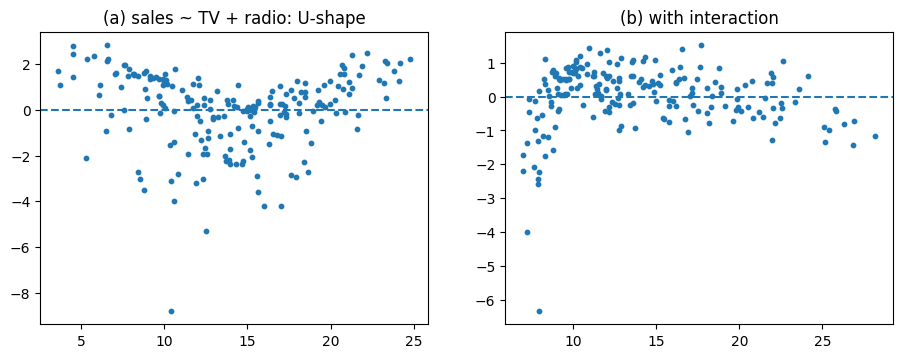

mean leverage: 0.015 = (p+1)/n = 0.015   flagged: 2


In [135]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (m, title) in zip(axes, [(m2, "(a) sales ~ TV + radio: U-shape"), (mi, "(b) with interaction")]):
    ax.scatter(m.fittedvalues, m.resid, s=10); ax.axhline(0, ls="--"); ax.set_title(title)
plt.show()
h2 = m2.get_influence().hat_matrix_diag
print("mean leverage:", round(h2.mean(), 4), "= (p+1)/n =", 3 / 200, "  flagged:", (h2 > 2 * 3 / 200).sum())   # 2 points

Slides: *Collinearity*, *Collinearity -- consequences in the credit data*, *Variance inflation factor (VIF)*

$$\operatorname{VIF}_j = \frac{1}{1 - R_j^2}$$

**In words:** `Limit` and `Rating` are almost identical (correlation 0.997): adding `Rating`
multiplies the SE of `Limit` by about 12.5; $\sqrt{\operatorname{VIF}} = \sqrt{160.6} = 12.7$.

In [136]:
print("corr(Limit, Rating) =", round(cr["Limit"].corr(cr["Rating"]), 3))
m_al = smf.ols("Balance ~ Age + Limit", data=cr).fit()
m_alr = smf.ols("Balance ~ Age + Limit + Rating", data=cr).fit()
for name, m in [("Age + Limit", m_al), ("Age + Limit + Rating", m_alr)]:
    print(f"{name:22s} beta_Limit {m.params['Limit']:.4f}  SE {m.bse['Limit']:.5f}  "
          f"T {m.tvalues['Limit']:.2f}  p {m.pvalues['Limit']:.2g}")
print("SE ratio:", round(m_alr.bse["Limit"] / m_al.bse["Limit"], 2), "  sqrt(VIF):",
      round(np.sqrt(1 / (1 - smf.ols("Limit ~ Age + Rating", data=cr).fit().rsquared)), 1))

corr(Limit, Rating) = 0.997
Age + Limit            beta_Limit 0.1734  SE 0.00503  T 34.50  p 1.6e-121
Age + Limit + Rating   beta_Limit 0.0190  SE 0.06296  T 0.30  p 0.76
SE ratio: 12.53   sqrt(VIF): 12.7


#### Exercise -- a diagnostics case study

House prices are regressed on `size`, `bedrooms`, `age` and `income` of the area
($n = 400$, $p = 4$). The diagnostics show:

- **Residual plot:** a clear U-shaped curve, and the spread of the residuals widens from left to right.
- **Leverage:** one point has $h_i = 0.30$.
- **VIF:** size 8.9, bedrooms 7.5, age 1.3, income 9.2.

Name every problem and suggest a remedy for each.

In [137]:
n, p, h_max = 400, 4, 0.30
vif = {"size": 8.9, "bedrooms": 7.5, "age": 1.3, "income": 9.2}
# Your turn

**Solution**

In [138]:
n, p, h_max = 400, 4, 0.30
vif = {"size": 8.9, "bedrooms": 7.5, "age": 1.3, "income": 9.2}
threshold = 2 * (p + 1) / n
print("leverage threshold:", threshold, "  h / threshold:", round(h_max / threshold, 1))     # 0.025, 12 times
print("VIF > 5:", [v for v, f in vif.items() if f > 5],
      "  SE inflation sqrt(VIF):", {v: round(float(np.sqrt(f)), 2) for v, f in vif.items()})
# U-shape: non-linearity (add size^2 or log size); widening spread: heteroscedasticity (log price);
# leverage: inspect the point, compare the fit with and without it; collinearity: drop or combine
# redundant variables (e.g. keep size, drop bedrooms) and recompute the VIFs

leverage threshold: 0.025   h / threshold: 12.0
VIF > 5: ['size', 'bedrooms', 'income']   SE inflation sqrt(VIF): {'size': 2.98, 'bedrooms': 2.74, 'age': 1.14, 'income': 3.03}


Slide: *Appendix -- Python commands*

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      6.7502      0.248     27.233      0.000       6.261       7.239
TV             0.0191      0.002     12.699      0.000       0.016       0.022
radio          0.0289      0.009      3.241      0.001       0.011       0.046
TV:radio       0.0011   5.24e-05     20.727      0.000       0.001       0.001


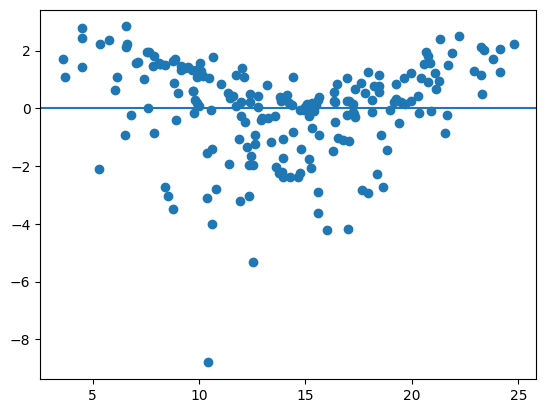

2


In [139]:
mi = smf.ols("sales ~ TV * radio", data=ad).fit()   # TV + radio + TV:radio
print(mi.summary().tables[1])
plt.scatter(m2.fittedvalues, m2.resid); plt.axhline(0)   # curvature?
plt.show()
h = m2.get_influence().hat_matrix_diag      # leverages h_i
print((h > 2 * (2 + 1) / 200).sum())        # high leverage (p = 2): 2 points

In [140]:
print(round(1 / (1 - smf.ols("Limit ~ Age + Rating", data=cr).fit().rsquared), 1))  # 160.6
from statsmodels.stats.outliers_influence import variance_inflation_factor
X = sm.add_constant(cr[["Age", "Limit", "Rating"]])
print([round(float(variance_inflation_factor(X.values, j)), 2) for j in (1, 2, 3)])  # 1.01 160.6 160.7

160.6
[1.01, 160.59, 160.67]


Slide: *Appendix summary*

**In words:** derivation via the normal equations; the OLS line is the unique minimum;
interactions make an effect depend on another variable; flag leverage $h_i > 2(p+1)/n$;
collinearity inflates standard errors by $\sqrt{\operatorname{VIF}_j}$.

## Key Python commands

```python
# Description and estimation
plt.scatter(df["x"], df["y"])              # scatter plot
df["x"].cov(df["y"]); df["x"].corr(df["y"])  # covariance, correlation
reg = smf.ols("y ~ x", data=df).fit()      # simple regression ("y explained by x")
b0, b1 = reg.params                        # estimates
plt.axline((0, b0), slope=b1)              # regression line
reg.predict(new)                           # prediction (new: data frame with column x)
print(reg.summary())                       # SE, t, p, R^2, F
reg.rsquared, reg.ssr, reg.ess, reg.centered_tss   # R^2, RSS, ESS, TSS
np.sqrt(reg.scale)                         # residual standard error sigma-hat

# Inference
reg.bse, reg.tvalues, reg.pvalues          # standard errors, t-statistics, p-values
reg.conf_int(alpha=0.05)                   # confidence intervals
stats.t.ppf(0.975, df=n - 2)               # critical value of the t-test
2 * stats.t.cdf(-abs(T), df=n - 2)         # two-sided p-value
reg.get_prediction(new).summary_frame()    # mean_ci_*: CI, obs_ci_*: prediction interval

# Multiple regression
m = smf.ols("y ~ x1 + x2 + x3", data=df).fit()
m.fvalue, m.f_pvalue, m.rsquared_adj       # F-test, adjusted R^2
stats.f.ppf(0.95, p, n - p - 1)            # critical value of the F-test
sm.stats.anova_lm(small, large)            # partial F-test: does a variable add anything?
smf.ols("y ~ x + Student", data=df).fit()  # text column -> dummy Student[T.Yes]

# Diagnostics (appendix)
plt.scatter(reg.fittedvalues, reg.resid); plt.axhline(0)   # residual plot
sm.qqplot(reg.resid, line="q", a=0.5)      # QQ-plot of the residuals
stats.norm.ppf((np.arange(1, n + 1) - 0.5) / n)   # normal quantiles z_i
reg.get_influence().hat_matrix_diag        # leverage values h_i
np.linalg.solve(A, b)                      # solve the normal equations
smf.ols("y ~ x1 * x2", data=df).fit()      # interaction x1 + x2 + x1:x2
variance_inflation_factor(X.values, j)     # VIF (X = sm.add_constant(...))
```